# What cost information is worth, when to stop paying, and when grants can end

**For the coauthors.** This notebook walks through the decision-value analysis
(`z-ethan/voi/`, 2026-09-09) that replaces the "cost of information" metrics in
Figure 5 and turns the demonstration-window year in Figure 6 from an assumption into
an output. It is written for a reader who knows the paper but not decision theory.
Every term of art is explained where it first appears. Every number below is read
from the analysis exports when this notebook runs. The analysis figures are embedded
as they are; four extra figures are drawn here only to explain them (a single cost
world's year-by-year decision, a bar summary of the losses, the distribution of
graduation years, and the two costs that the window year trades off).

**The one-paragraph version.** The paper prices the subsidy each deployment schedule
needs in 10,000 cost worlds. Two policy questions follow: how much does it cost the
government *not* to know which world it is in, and what does watching the first
completed units buy? Figure 5 answered with precision metrics (how much is spent when
an alarm fires; how wide an uncertainty band stays). Precision is not value: a wide
band is harmless if the decision does not depend on it. The standard tools of
decision analysis put the answers in dollars and turn the alarm into a rule that
minimizes expected loss. Three things come out. First, watching the first units
recovers most of the decision value even though the credit-scale band never gets
narrow. Second, the stop-or-continue rule has an explicit price of a false stop, and
today's 5% false-alarm budget turns out to price a false stop at roughly one
median-world bill. Third, the grant window has diminishing returns because worlds
either graduate early or never; all but a few percent of the worlds that ever graduate have
done so by 2038 in every schedule, so the paper's Figure 6 carries one common window end, 2038, and Table 2
reports the shares (Ethan, 2026-09-10). The per-schedule expected-loss minimizers below
are the SI's detail.

**Register.** Information, never a recommendation. No benefit of nuclear delivery is
priced anywhere. Where two error costs must be traded off, the exchange rate is a
parameter the reader supplies, and the paper's own 90%-coverage rule is shown to be
one value of it.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import Image, Markdown, display
import sys
sys.path.insert(0, str(Path.cwd().parent))
import plotstyle as ps
ps.apply()

HERE = Path.cwd()
assert HERE.name == "voi", f"run from z-ethan/voi/, not {HERE}"
REPO = HERE.parents[1]
EXP, FIG = HERE / "exports", HERE / "figures"
PF = REPO / "z-ethan" / "paper_figures" / "figures"
BD = REPO / "z-ethan" / "bridge_detection" / "exports"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

S = ["eia", "aj", "iaea", "mck", "cop28", "eo"]
NAME = {"eia": "EIA AEO high", "aj": "Abou-Jaoude", "iaea": "IAEA high", "mck": "McKinsey",
        "cop28": "COP28", "eo": "2025 EO"}
GW = {"eia": 117, "aj": 134, "iaea": 172, "mck": 200, "cop28": 300, "eo": 400}
YEARS = np.arange(2031, 2051)

p10 = pd.read_csv(EXP / "p10_prior_evpi.csv"); p11 = pd.read_csv(EXP / "p11_evppi.csv")
p12 = pd.read_csv(EXP / "p12_evsi_curves.csv"); p20 = pd.read_csv(EXP / "p20_stopping_bayes.csv")
p21 = pd.read_csv(EXP / "p21_stopping_lsmc.csv"); p22 = pd.read_csv(EXP / "p22_conformal_reference.csv")
p30 = pd.read_csv(EXP / "p30_graduation_year.csv"); p31 = pd.read_csv(EXP / "p31_cutoff_frontier.csv")
p33 = pd.read_csv(EXP / "p33_abandonment_bayes.csv"); p34 = pd.read_csv(EXP / "p34_window_decision.csv")
p35 = pd.read_csv(EXP / "p35_marginal_cost_ladder.csv"); p90 = pd.read_csv(EXP / "p90_verdict.csv").set_index("name")

# the median-world bill per schedule (2024 $B): the cap X at 1.5x divided by 1.5
_h = p20[(p20["mult"] == 1.5)].drop_duplicates("schedule").set_index("schedule")
P50 = {ab: float(_h.loc[ab, "X_B"]) / 1.5 for ab in S}
# the posterior-summary cache and the truth-world indices (same seed and order as the analysis)
ZC = np.load(EXP / "p00_posterior_summaries.npz")
_rng = np.random.default_rng(20260901)
TRUTH = {ab: np.sort(_rng.choice(10000, size=500, replace=False)) for ab in S}
BW = np.load(BD / "b07_bills_perworld_5a.npz")

def show(path, width=1400):
    assert Path(path).exists(), path
    display(Image(filename=str(path), width=width))

def table(df, fmt=None):
    df = df.copy()
    if "schedule" in df.columns:
        df["schedule"] = df["schedule"].map(lambda s: f"{NAME[s]} ({GW[s]} GW)")
    display(df.style.hide(axis="index").format(fmt or {}, na_rep="—"))

def rng_(s, nd=1):
    return f"{s.min():.{nd}f}–{s.max():.{nd}f}"

gates = p90.loc[["G0", "G1", "G2", "G3", "G4", "G4a", "G5"], "result"]
assert all(str(v).startswith("PASS") for v in gates), gates
print("analysis exports loaded; all hard gates PASS")


analysis exports loaded; all hard gates PASS


## 1. Why the old Figure 5 metrics were replaced

The figure below is the Figure 5 that stood until 2026-09-09. Panel (a) reported how
much subsidy is already committed when a spending-cap alarm fires; the alarm used a
fixed 5% false-alarm budget. Panel (b) reported the width of the 90% uncertainty band
on the required credit scale against a five-point tolerance. Both are precision
metrics. Neither says what a decision maker loses by not knowing, nor what
observation is worth.

**The replacement, in plain words.**

- **EVPI** (expected value of perfect information): the expected loss a decision maker
  would avoid by learning the true cost world before deciding. It is the ceiling on
  what any observation program can be worth.
- **EVPPI** (expected value of partial perfect information): the same for one input at
  a time — which uncertainty is worth resolving.
- **EVSI** (expected value of sample information): what the noisy costs of the units
  actually completed by year *k* are worth, computed before seeing them. It can never
  exceed EVPI.
- **Expected loss and the Bayes rule**: the expected loss of a decision rule is its
  loss averaged over the cost worlds; the Bayes rule is the rule with the smallest
  expected loss. For the stop-or-continue decision this replaces "hold false alarms
  to 5%" with "stop when the probability of overrunning reaches the threshold that
  minimizes expected loss at a stated price of a false stop".

These are the standard tools of decision analysis (Raiffa and Schlaifer's
preposterior analysis; the health-technology literature's EVPI/EVPPI/EVSI; Wald's
sequential decision theory). The one modeling choice is the loss function, and it was
chosen to coincide with the paper's own rule: the loss weights a unit of credit
shortfall α/(1−α) times a unit of credit excess, whose optimal act under any belief
is the α-quantile of the required scale. At α = 0.90 that is exactly "cover the
requirement in 90% of cost worlds". Everything is registered in `methods.md` before
the run, with gates that force the new code to reproduce the paper's frozen tables
exactly before it computes anything new.

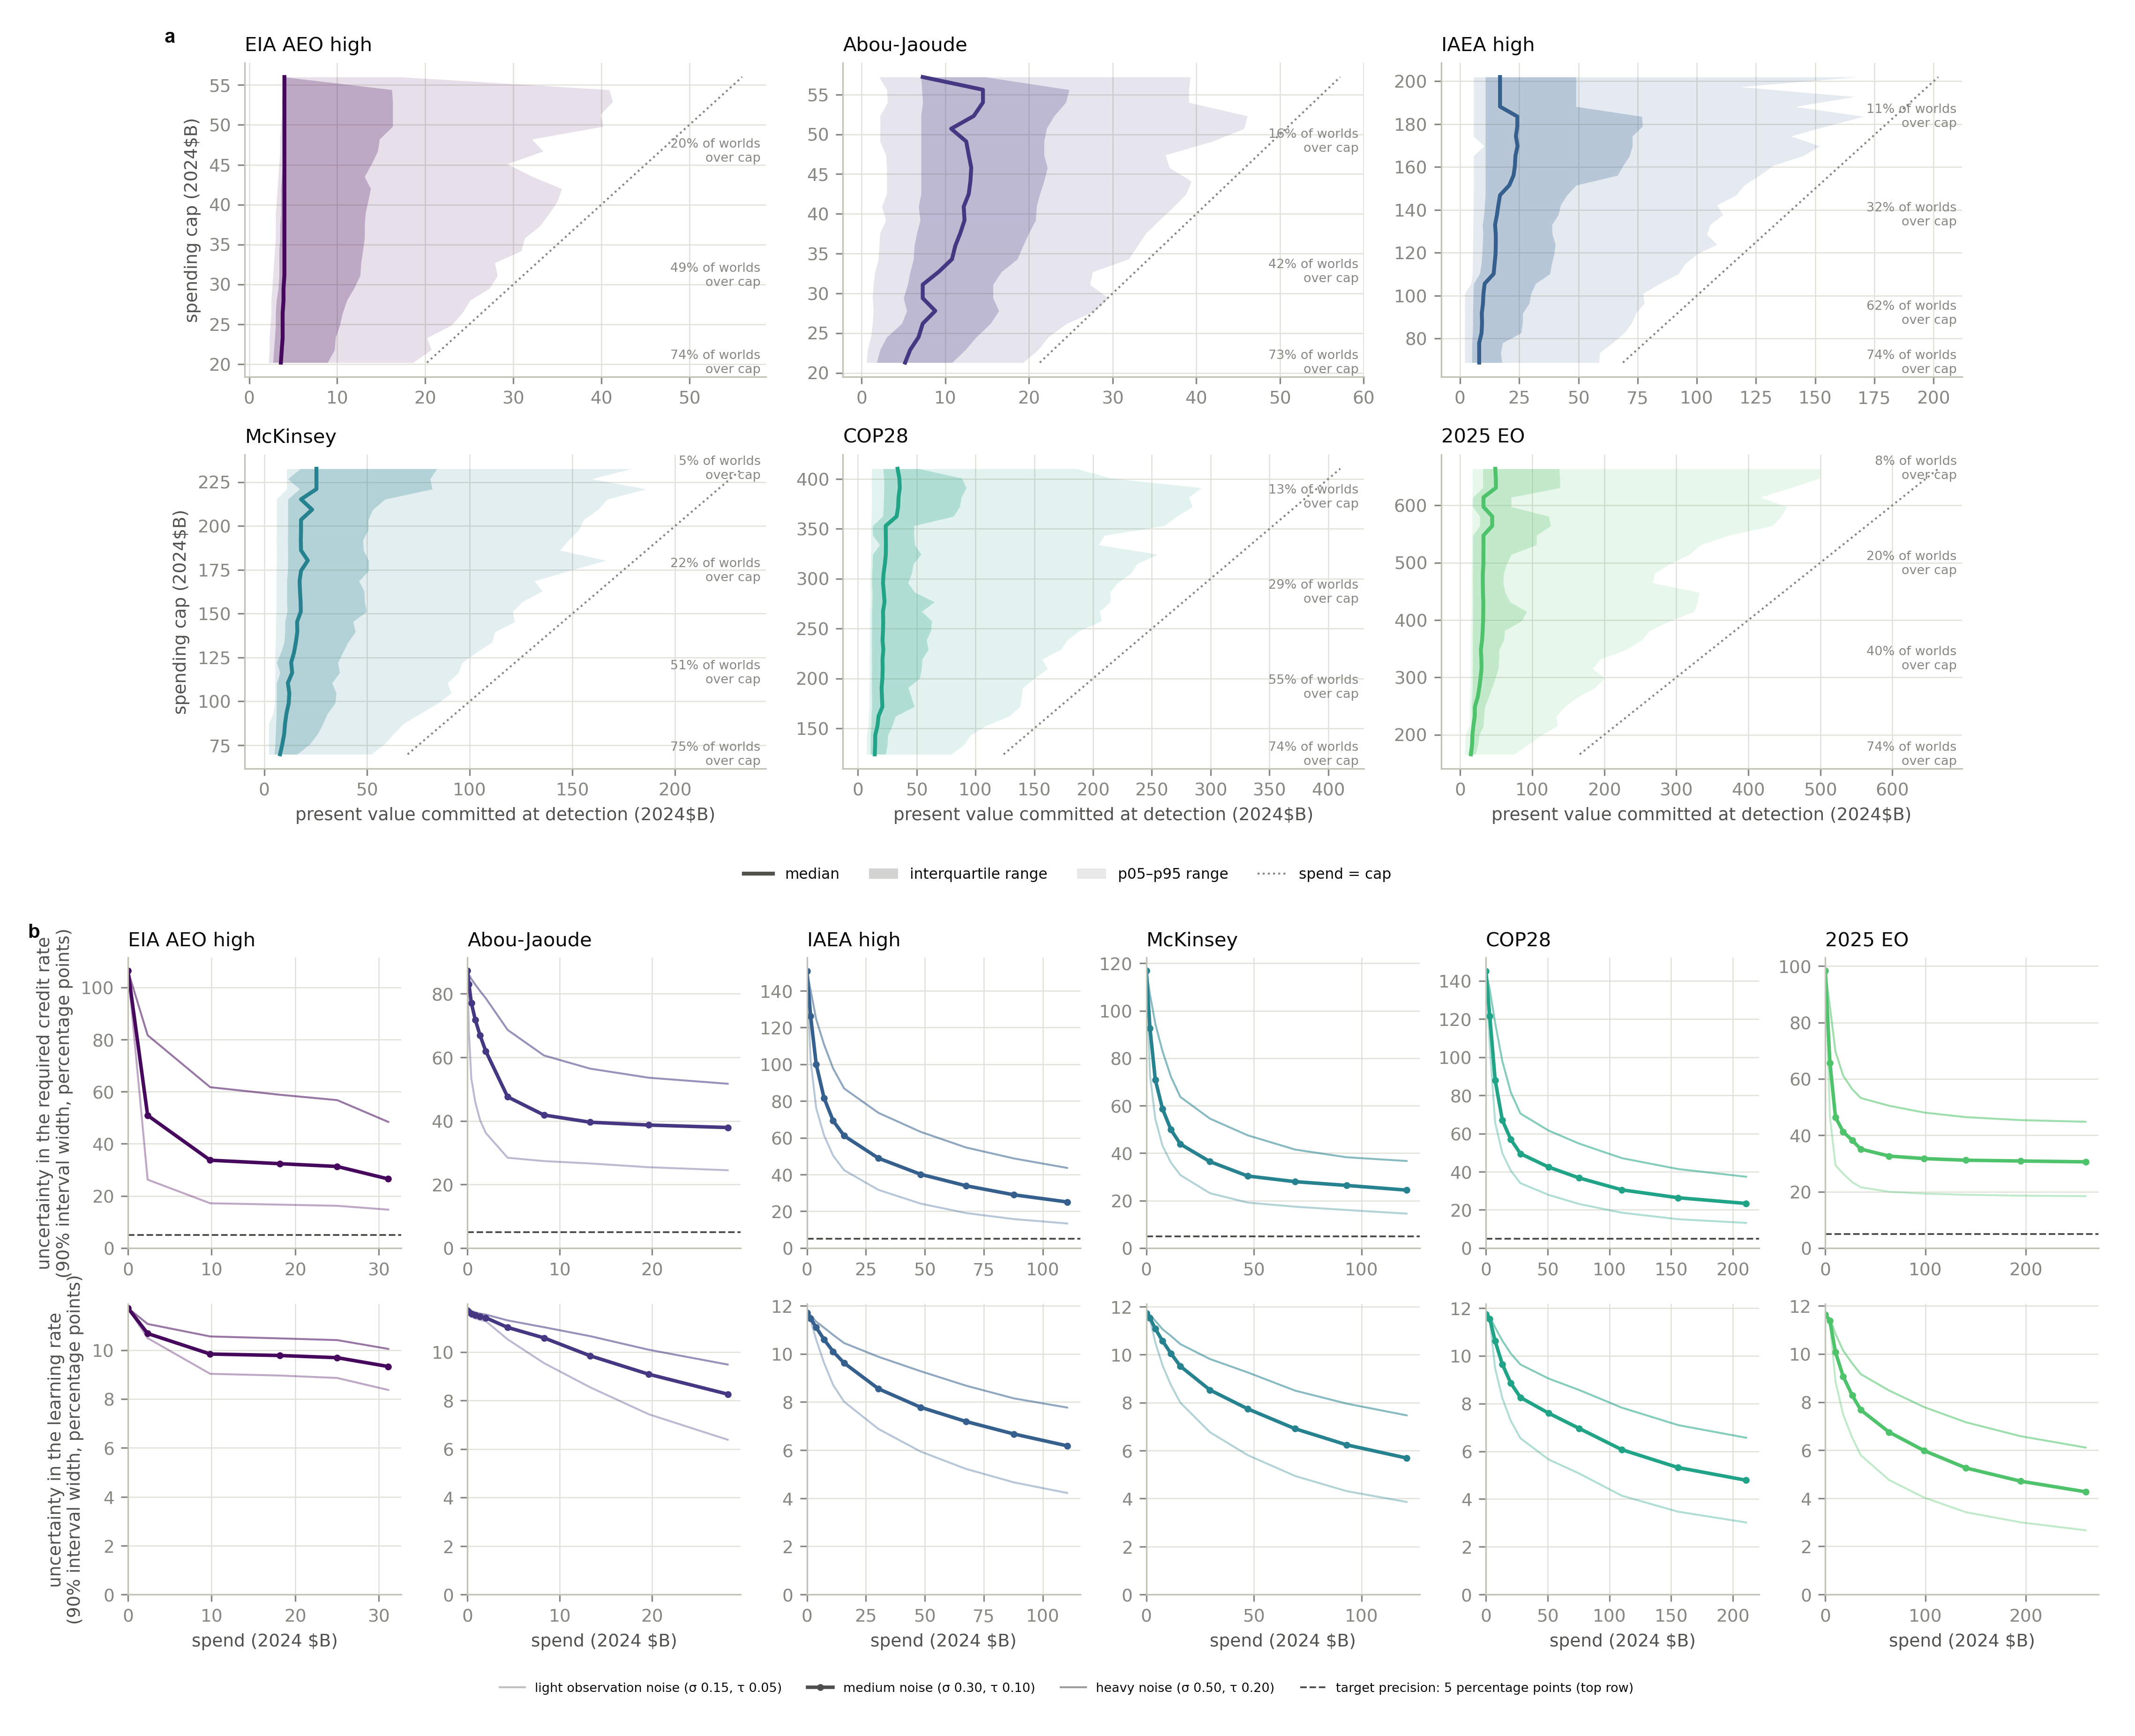

*The Figure 5 that stood until 2026-09-09 — precision metrics: committed spend at a fixed-budget alarm (a) and uncertainty-band width against a tolerance (b).*

In [2]:
show(PF / "Fig5_cost_of_detection.png", width=1000)
display(Markdown("*The Figure 5 that stood until 2026-09-09 — precision metrics: committed spend at a "
                 "fixed-budget alarm (a) and uncertainty-band width against a tolerance (b).*"))


## 2. Two things to know before the plots

**The median-world bill.** Each schedule's subsidy bill (the present value of the
support the mandated build needs, 2024 dollars) differs by cost world. The bill in
the median cost world is the natural size unit for that program. The six programs
differ in size by an order of magnitude, so a loss of "ten billion dollars" means
different things for EIA and for the Executive Order schedule. That is why the
analysis expressed prices as multiples of the median-world bill: a price of 1 means
"wrongly killing this program is as bad as wasting its whole expected bill". After
the first read-through the plots were changed to show **dollars on the bottom axis
and the multiple on the top axis**, so both readings are available.

**The posterior probability of overrunning.** Each year the government knows two
things: the costs of the units completed so far (noisy: per-project scatter plus a
shared industry shock) and its own outlay ledger (exact). From these it can compute,
for a spending cap X, the probability that the program's total bill will end up above
X: the share of the 10,000 candidate cost worlds that fit the observations and whose
remaining bill, added to what is already spent, exceeds X. That probability starts at
the prior share of worlds over the cap and moves as evidence accumulates. Every rule
in sections 4 and 5 is a rule about that probability.

In [3]:
h = p20[(p20["sigma"] == 0.3) & (p20["mult"] == 1.5) & (p20["rho"] == 1.0)].set_index("schedule").reindex(S)
t = pd.DataFrame({"schedule": S, "median-world bill (2024 $B)": [P50[s] for s in S],
                  "spending cap at 1.5x (2024 $B)": h["X_B"].values,
                  "share of cost worlds whose bill exceeds that cap": h["prior_exceed_sample"].values,
                  "a false-stop price of 1 means (2024 $B)": [P50[s] for s in S]})
table(t, {"median-world bill (2024 $B)": "{:.0f}", "spending cap at 1.5x (2024 $B)": "{:.0f}",
          "share of cost worlds whose bill exceeds that cap": "{:.2f}", "a false-stop price of 1 means (2024 $B)": "{:.0f}"})


schedule,median-world bill (2024 $B),spending cap at 1.5x (2024 $B),share of cost worlds whose bill exceeds that cap,a false-stop price of 1 means (2024 $B)
EIA AEO high (117 GW),31,47,0.17,31
Abou-Jaoude (134 GW),33,49,0.19,33
IAEA high (172 GW),92,138,0.29,92
McKinsey (200 GW),116,174,0.25,116
COP28 (300 GW),191,286,0.31,191
2025 EO (400 GW),332,498,0.22,332


## 3. Result A — the value of watching the first units

**The decision.** Declare a scale on the reference credit path (the p50 anchor's
declared $/kW path). A world is delivered in a year if the scaled reference covers
its need that year. After the units of year *k* are observed, the years already
built are sunk at the prior act and only the later years are re-priced, so the value
of watching is a quasi-option value: the information arrives only because building
proceeds.

**How to read the figure.** Top row: the expected value of the observations so far,
in 2024 billion dollars of avoided loss, against the spend committed before the
observation; three noise levels and the near-perfect-observation limit. The dashed
line is the value of perfect information about the years still to be priced; it
falls as years become sunk. Bottom row: the share of that remaining value the
observations recover.

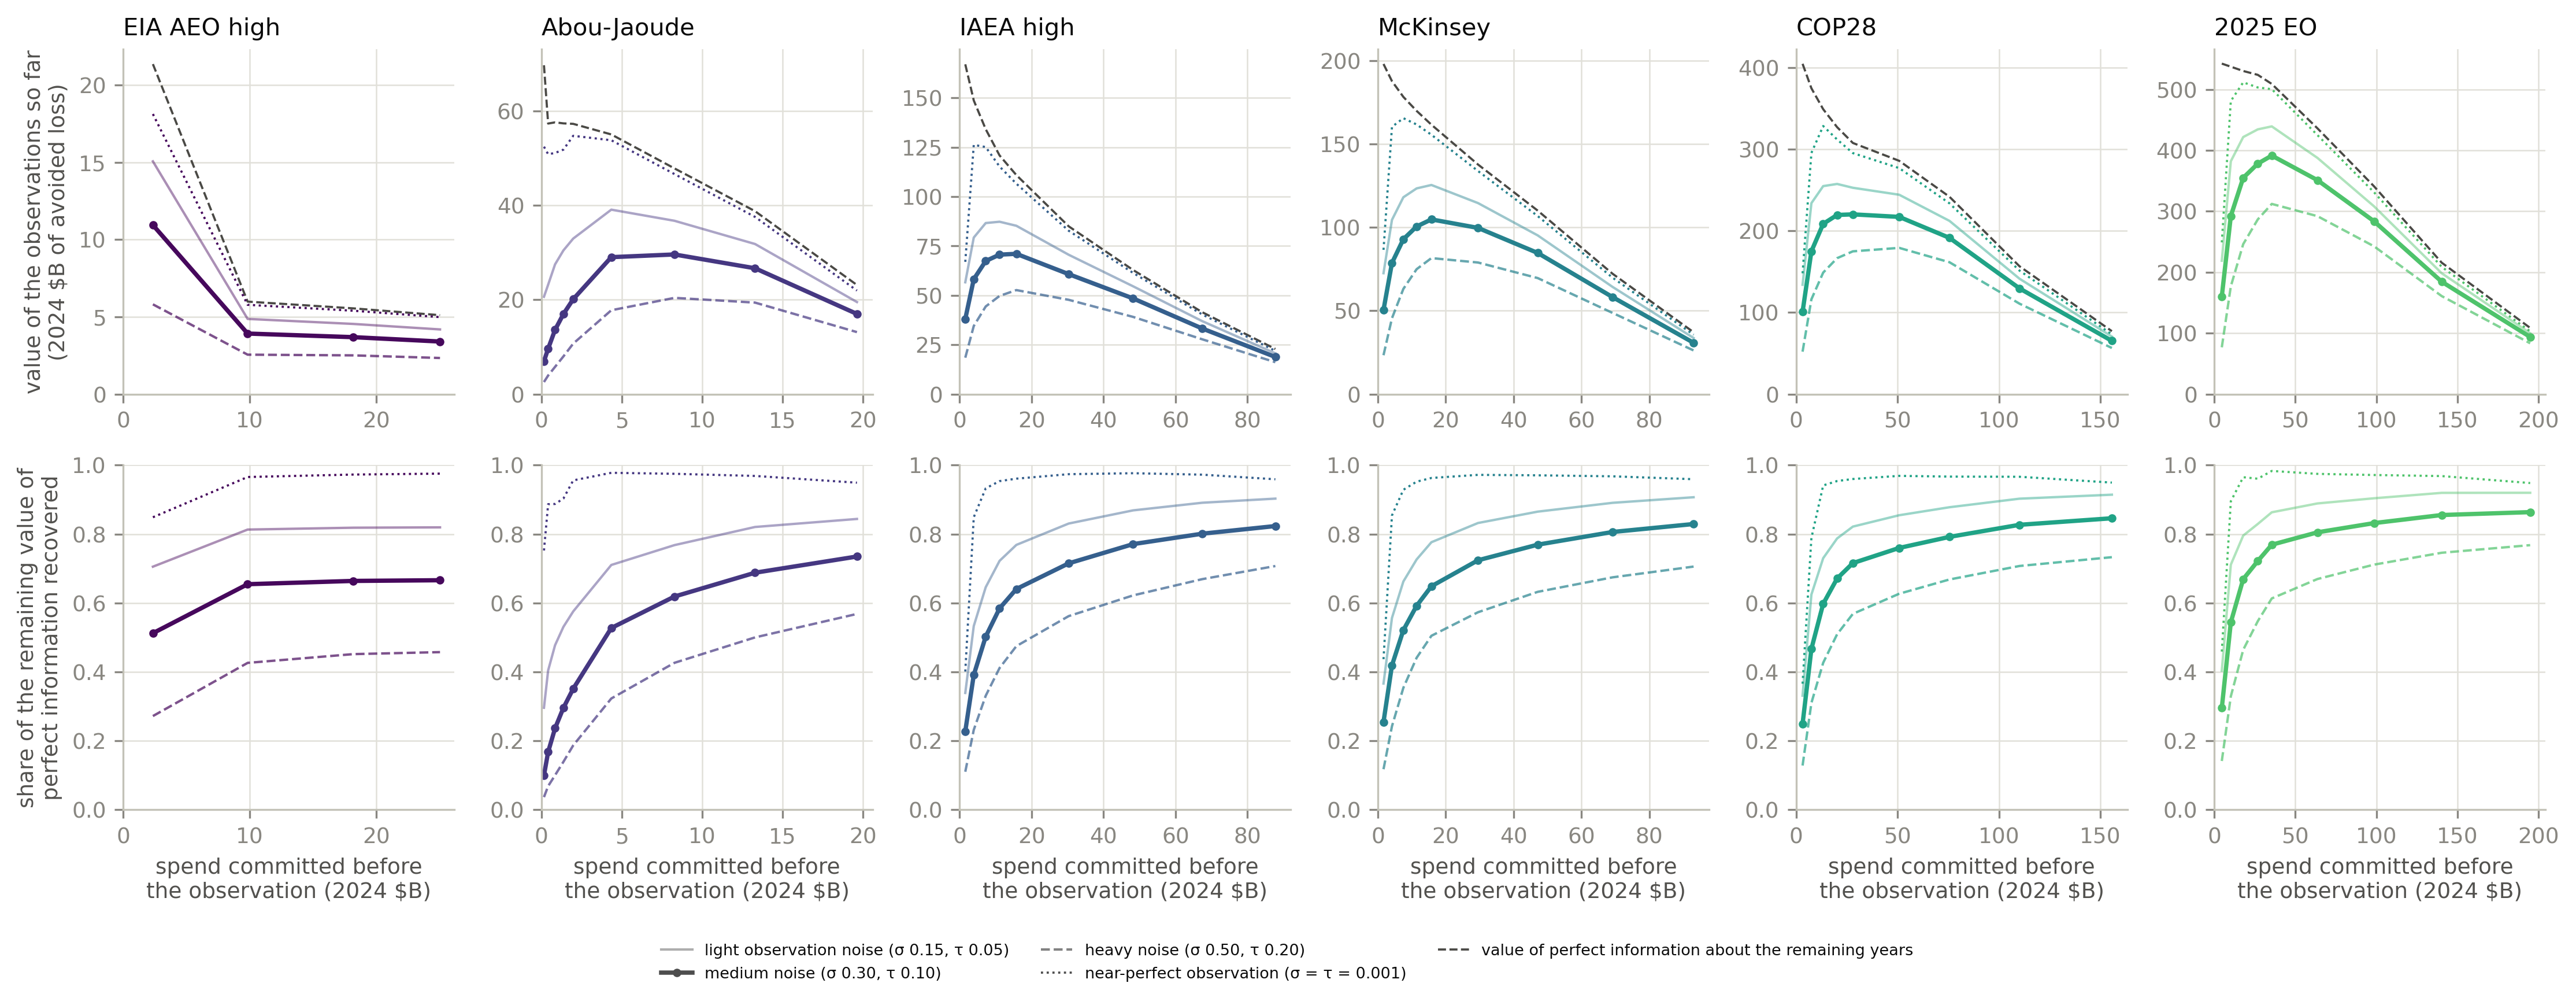

schedule,prior 90% act (x reference path),outlay of that act (B$),"EVPI, full horizon (B$)",EVSI after the first observation (B$),first-observation year,share of remaining EVPI recovered by the last usable observation (medium noise),"same, light noise","same, heavy noise"
EIA AEO high (117 GW),1.93,110.9,49.5,10.9,2038,0.67,0.82,0.46
Abou-Jaoude (134 GW),1.98,169.1,68.6,7.0,2031,0.73,0.84,0.57
IAEA high (172 GW),2.29,421.4,192.2,38.0,2031,0.82,0.90,0.71
McKinsey (200 GW),2.06,468.7,206.0,50.4,2031,0.83,0.91,0.71
COP28 (300 GW),2.28,953.4,440.4,100.8,2031,0.85,0.91,0.73
2025 EO (400 GW),2.06,1289.9,473.1,160.1,2031,0.86,0.92,0.77



**What the numbers say.** Before any unit is built, the prior 90% act over-pays the perfect act by
**49.5–473.1 B$** in expectation across the six schedules (the full-horizon EVPI; a
lower bound at this coverage level because the most expensive worlds sit on the requirement map's top
clamp — disclosure K2). The first year of completed units is worth **7.0–160.1 B$**
of avoided loss on its own. By the last observation that can still change a decision, the
observations recover **0.67–0.86** of the value of perfect information
about the remaining years at medium noise (0.82–0.92 light, 0.46–0.77 heavy).

**Implication for the paper.** The registered prediction was that the observations would recover
*less than half* of the remaining value — the dollar restatement of the "calibration limit" in the old
Figure 5b, where the credit-scale band never narrows below 24–39 points. The prediction **missed in the
informative direction**: the band stays wide, yet most of the decision value is recovered. The two are
consistent — the dollar loss loads on the anchor cost, which the first units reveal, while the learning
rate stays uncertain and the scale-space band with it — but they lead a reader to opposite conclusions.
S3-3's "observation tells the government when to stop paying, not how much to pay" needs to become
"observation tells the government most of what it needs to know about how much to pay, and early; what
it cannot do is narrow the learning rate".


In [4]:
show(FIG / "y01_evsi_curves.png")
h = p12[(p12["alpha"] == 0.9) & (p12["sigma"] == 0.3) & (p12["k"] >= 0)]
first = h[h["k"] == 0].set_index("schedule").reindex(S)
last = h[h["k"] == h.groupby("schedule")["k"].transform("max")].set_index("schedule").reindex(S)
pri = p12[(p12["alpha"] == 0.9) & (p12["sigma"] == 0.3) & (p12["k"] == -1)].set_index("schedule").reindex(S)
noise = {lv: p12[(p12["alpha"] == 0.9) & (p12["sigma"] == lv) & (p12["k"] >= 0)]
         .pipe(lambda d: d[d["k"] == d.groupby("schedule")["k"].transform("max")]).set_index("schedule")
         ["frac_recovered_dollar"].reindex(S) for lv in (0.15, 0.3, 0.5)}
t = pd.DataFrame({
    "schedule": S,
    "prior 90% act (x reference path)": pri["f_prior"].values,
    "outlay of that act (B$)": (pri["f_prior"] * pri["spref_res_B"]).values,
    "EVPI, full horizon (B$)": pri["evpi_dollar_B"].values,
    "EVSI after the first observation (B$)": first["evsi_dollar_B"].values,
    "first-observation year": first["year"].values,
    "share of remaining EVPI recovered by the last usable observation (medium noise)": last["frac_recovered_dollar"].values,
    "same, light noise": noise[0.15].values, "same, heavy noise": noise[0.5].values,
})
table(t, {c: "{:.2f}" for c in t.columns if "act" in c or "share" in c or "same" in c} | {c: "{:.1f}" for c in t.columns if "B$" in c})
display(Markdown(f'''
**What the numbers say.** Before any unit is built, the prior 90% act over-pays the perfect act by
**{rng_(pri["evpi_dollar_B"])} B$** in expectation across the six schedules (the full-horizon EVPI; a
lower bound at this coverage level because the most expensive worlds sit on the requirement map's top
clamp — disclosure K2). The first year of completed units is worth **{rng_(first["evsi_dollar_B"])} B$**
of avoided loss on its own. By the last observation that can still change a decision, the
observations recover **{rng_(last["frac_recovered_dollar"], 2)}** of the value of perfect information
about the remaining years at medium noise ({rng_(noise[0.15], 2)} light, {rng_(noise[0.5], 2)} heavy).

**Implication for the paper.** The registered prediction was that the observations would recover
*less than half* of the remaining value — the dollar restatement of the "calibration limit" in the old
Figure 5b, where the credit-scale band never narrows below 24–39 points. The prediction **missed in the
informative direction**: the band stays wide, yet most of the decision value is recovered. The two are
consistent — the dollar loss loads on the anchor cost, which the first units reveal, while the learning
rate stays uncertain and the scale-space band with it — but they lead a reader to opposite conclusions.
S3-3's "observation tells the government when to stop paying, not how much to pay" needs to become
"observation tells the government most of what it needs to know about how much to pay, and early; what
it cannot do is narrow the learning rate".
'''))


### Which uncertainty is worth resolving

EVPPI asks the same question one input at a time. The estimator bins the 10,000
worlds on the input and fits the 90% act within each bin, with two safeguards: the
fit uses half of each bin's worlds and is scored on the other half, and the input is
shuffled twenty times to measure the value an uninformative input would show by
chance (the noise floor, drawn as error bars).

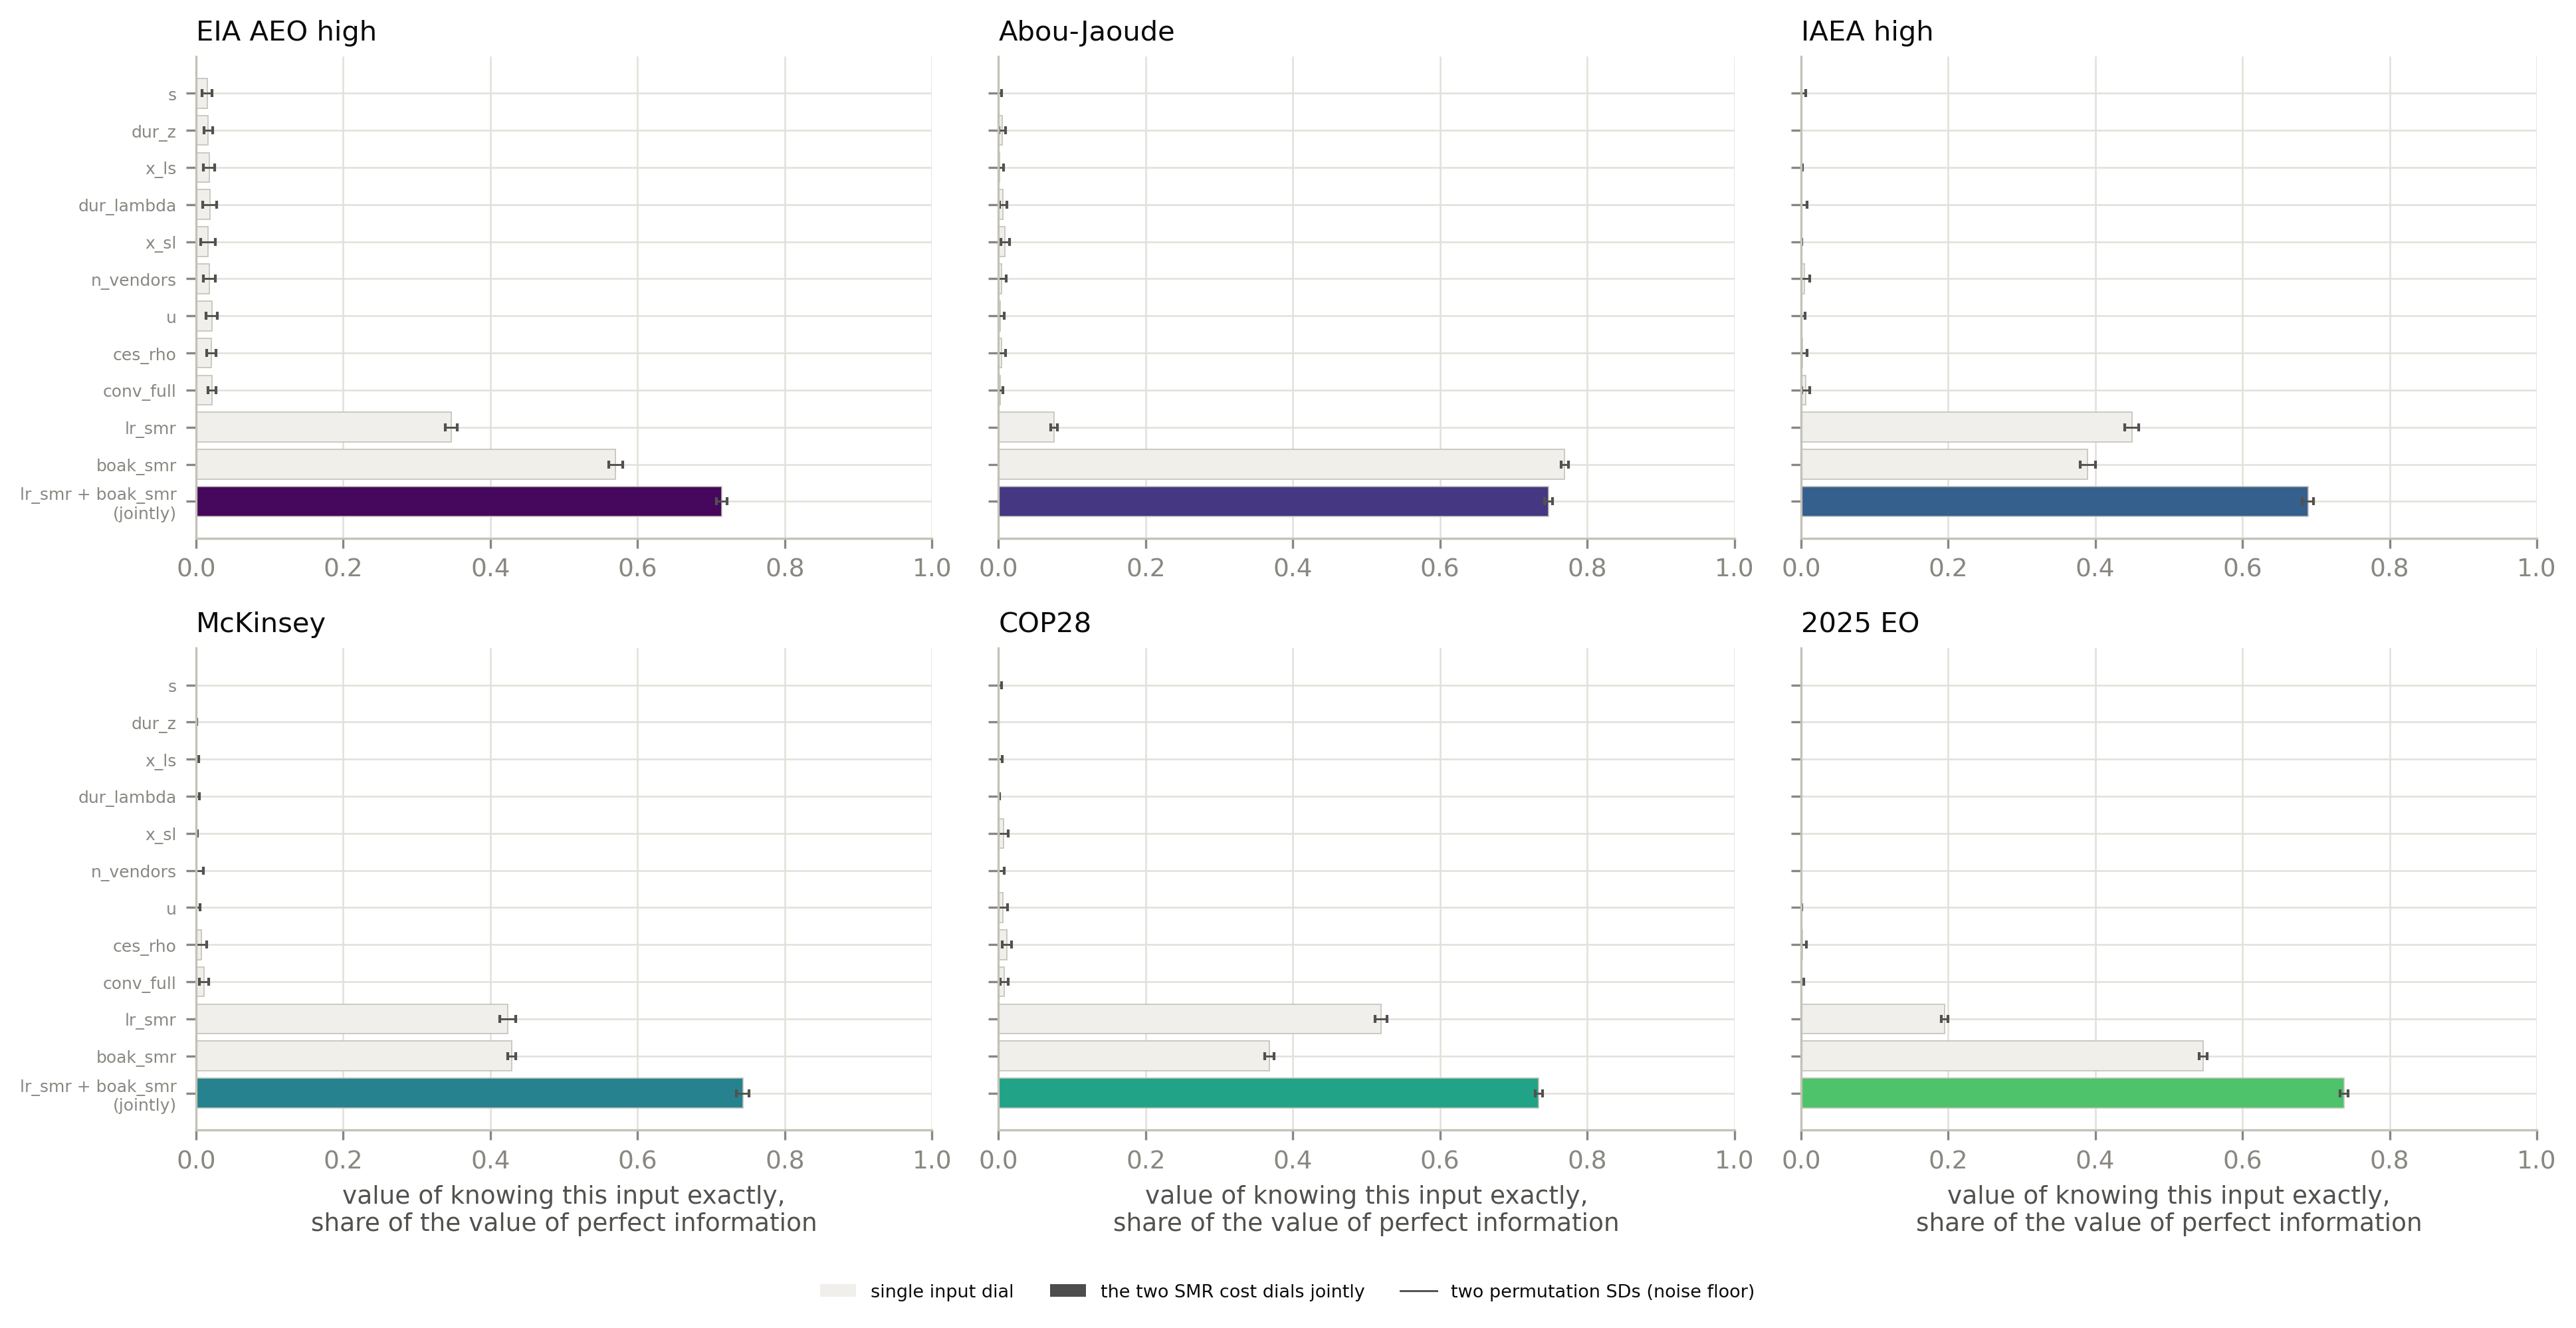


**What the numbers say.** The SMR anchor cost alone is worth **0.37–0.77** of EVPI and the SMR
learning rate **0.08–0.52**; the two together **0.69–0.75**. Every other dial sits at or below
the permutation noise floor (best single-dial share 0.02).

**Implication.** Of the thirteen cost-world dials only two matter for the subsidy decision, and the
anchor cost matters at least as much as the learning rate in 4 of six schedules.
That is why the first completed units are so valuable: they pin the anchor. The registered prediction
that the two dials jointly carry at least 70% of EVPI missed by a hair in one schedule (IAEA
0.689); it is reported as missed.


In [5]:
show(FIG / "y02_evppi.png")
h11 = p11[(p11["alpha"] == 0.9) & (p11["bins"].isin([49, 50]))]
grp = h11[h11["dial"].str.startswith("group")].set_index("schedule")["share_of_evpi_dollar"].reindex(S)
boak = h11[h11["dial"] == "boak_smr"].set_index("schedule")["share_of_evpi_dollar"].reindex(S)
lr = h11[h11["dial"] == "lr_smr"].set_index("schedule")["share_of_evpi_dollar"].reindex(S)
rest = h11[~h11["dial"].isin(["boak_smr", "lr_smr", "boak_large", "lr_large"]) & ~h11["dial"].str.startswith("group")]
display(Markdown(f'''
**What the numbers say.** The SMR anchor cost alone is worth **{rng_(boak, 2)}** of EVPI and the SMR
learning rate **{rng_(lr, 2)}**; the two together **{rng_(grp, 2)}**. Every other dial sits at or below
the permutation noise floor (best single-dial share {rest["share_of_evpi_dollar"].max():.2f}).

**Implication.** Of the thirteen cost-world dials only two matter for the subsidy decision, and the
anchor cost matters at least as much as the learning rate in {int((boak >= lr).sum())} of six schedules.
That is why the first completed units are so valuable: they pin the anchor. The registered prediction
that the two dials jointly carry at least 70% of EVPI missed by a hair in one schedule (IAEA
{grp["iaea"]:.3f}); it is reported as missed.
'''))


## 4. Result B — when to stop paying

**The question the government faces.** Suppose Congress sets a spending cap for the
program: here, one and a half times the bill in the median cost world. Every year the
government sees the costs of the reactors completed that year and its own outlay
ledger, and asks: *given what I have seen, how likely is it that this program will
blow through the cap?* If that probability gets high enough, it stops the program and
saves the rest of the money. Two things can go wrong:

- **Stopping too late** in a world that really is expensive: every dollar paid before
  the stop is wasted, because the program is abandoned anyway. (The cap itself is a
  backstop: at the latest, the program stops when spend reaches the cap.)
- **Stopping wrongly** in a world that would have stayed under the cap: a program
  that would have delivered is killed. The paper does not put a dollar value on
  nuclear delivery, so this cost is left to the reader as a **price of a false stop**.

The Bayes rule is then simple: stop the first year the probability of overrunning
reaches a threshold, and set the threshold to minimize the expected loss
(wasted spend in expensive worlds plus the false-stop price times the chance of
stopping a good world). A high price of a false stop means a high threshold — you
need to be very sure before you pull the plug. The old Figure 5a instead fixed the
false-alarm rate at 5% and never said what that implied about the price.

### One cost world, year by year

The figure below is drawn from the analysis cache for one schedule (McKinsey) and
two of its 10,000 cost worlds: one whose true bill exceeds the cap and one whose
bill does not, each seen through one noisy observation history at medium noise.
Top: the government's year-by-year probability that the bill will exceed the cap, with
the Bayes threshold at a false-stop price of one median-world bill, and the year the
rule stops. Bottom: the cumulative spend in each world against the cap; the shaded
part is what the rule saves compared with waiting for the cap.

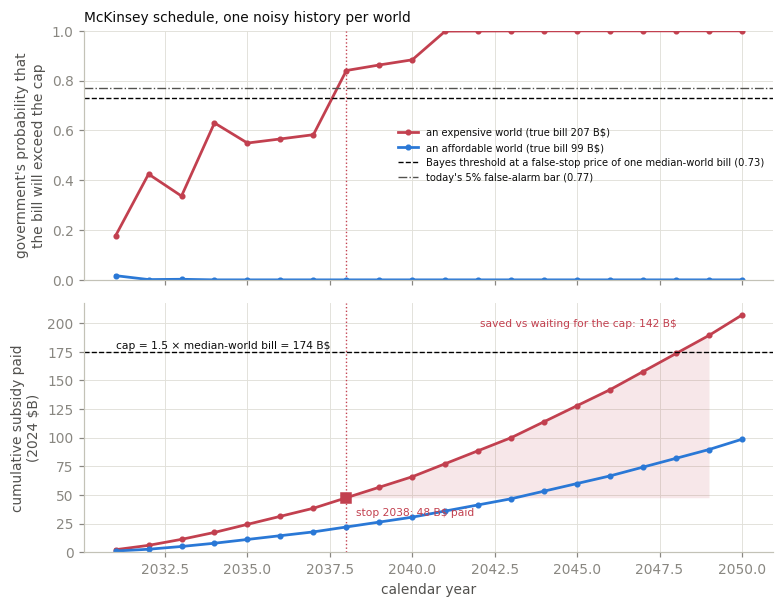


**Reading it.** In the expensive world the probability of overrunning climbs as the first units come in
expensive; the rule stops when it crosses 0.73, having paid a fraction of what waiting for the cap
would cost. In the affordable world the probability drifts down and the rule never fires; the program
runs to completion. A rule with a lower threshold would stop the expensive world earlier (saving more)
but would fire on some affordable worlds too (false stops). Where to set the threshold is exactly the
trade-off the false-stop price resolves.


In [6]:
ab, x_i = "mck", 2                       # McKinsey, cap 1.5x
X = 1.5 * P50[ab]
ex = ZC[f"{ab}|s30t10|ex"][:, :, :, x_i]         # (500 truth worlds, 10 histories, 20 years)
tr = TRUTH[ab]
b2050 = BW[f"b2050_{ab}"][tr]; bills = BW[f"bills_{ab}"][tr]
is_ex = b2050 > X
pib = float(p20[(p20["schedule"] == ab) & (p20["sigma"] == 0.3) & (p20["mult"] == 1.5) & (p20["rho"] == 1.0)]["pi_bar_opt"].iloc[0])
bar5 = float(p22[(p22["schedule"] == ab) & (p22["sigma"] == 0.3) & (p22["mult"] == 1.5)]["bar"].iloc[0])
# the exceeding world nearest the median exceeding bill; the non-exceeding world nearest its median
w_ex = int(np.flatnonzero(is_ex)[np.argmin(np.abs(b2050[is_ex] - np.median(b2050[is_ex])))])
w_ok = int(np.flatnonzero(~is_ex)[np.argmin(np.abs(b2050[~is_ex] - np.median(b2050[~is_ex])))])
r = 0
def first_stop(post, spend):
    hit = np.flatnonzero((post >= pib) | (spend > X))
    return int(hit[0]) if len(hit) else None
fig, axes = plt.subplots(2, 1, figsize=(ps.W2 * 0.8, 5.6), sharex=True)
ax, axl = axes
for w, col, lab in [(w_ex, ps.ACCENT["red"], f"an expensive world (true bill {b2050[w_ex]:.0f} B$)"),
                    (w_ok, ps.ACCENT["blue"], f"an affordable world (true bill {b2050[w_ok]:.0f} B$)")]:
    post = ex[w, r]; spend = bills[w]
    ax.plot(YEARS, post, color=col, lw=1.8, marker="o", ms=3, label=lab)
    axl.plot(YEARS, spend, color=col, lw=1.8, marker="o", ms=3)
    j = first_stop(post, spend)
    if j is not None:
        ax.axvline(YEARS[j], color=col, lw=0.9, ls=":")
        axl.axvline(YEARS[j], color=col, lw=0.9, ls=":")
        axl.plot([YEARS[j]], [spend[j]], marker="s", ms=6, color=col)
        axl.annotate(f"stop {YEARS[j]}: {spend[j]:.0f} B$ paid", (YEARS[j], spend[j]), textcoords="offset points",
                     xytext=(6, -12), fontsize=7, color=col)
        if w == w_ex:
            jl = int(np.flatnonzero(spend > X)[0]) if (spend > X).any() else 19
            axl.fill_between(YEARS[j:jl + 1], spend[j:jl + 1], spend[j], color=col, alpha=0.12, lw=0)
            axl.annotate(f"saved vs waiting for the cap: {spend[jl] - spend[j]:.0f} B$", (YEARS[jl], spend[jl]),
                         textcoords="offset points", xytext=(-150, 6), fontsize=7, color=col)
ax.axhline(pib, color="k", lw=0.9, ls="--", label=f"Bayes threshold at a false-stop price of one median-world bill ({pib:.2f})")
ax.axhline(bar5, color=ps.MUTED, lw=0.9, ls="-.", label=f"today's 5% false-alarm bar ({bar5:.2f})")
ax.set_ylim(0, 1); ax.set_ylabel("government's probability that\nthe bill will exceed the cap")
ax.legend(fontsize=6.5, frameon=False, loc="center right")
axl.axhline(X, color="k", lw=0.9, ls="--"); axl.text(2031, X * 1.02, f"cap = 1.5 × median-world bill = {X:.0f} B$", fontsize=7)
axl.set_ylabel("cumulative subsidy paid\n(2024 $B)"); axl.set_xlabel("calendar year"); axl.set_ylim(0, None)
ax.set_title(f"{NAME[ab]} schedule, one noisy history per world", fontsize=9, loc="left")
fig.tight_layout(); plt.show()
display(Markdown(f'''
**Reading it.** In the expensive world the probability of overrunning climbs as the first units come in
expensive; the rule stops when it crosses {pib:.2f}, having paid a fraction of what waiting for the cap
would cost. In the affordable world the probability drifts down and the rule never fires; the program
runs to completion. A rule with a lower threshold would stop the expensive world earlier (saving more)
but would fire on some affordable worlds too (false stops). Where to set the threshold is exactly the
trade-off the false-stop price resolves.
'''))


### What the rule buys, program by program

Before the frontier plots, the same result as three bars per schedule at a
false-stop price of one median-world bill: the expected loss with no cost
surveillance (the cap alone), the expected loss under the Bayes rule, and the
expected loss with perfect information (zero: an all-knowing government never pays
into a program that will overrun). The gap between the first two bars is the value of
watching costs.

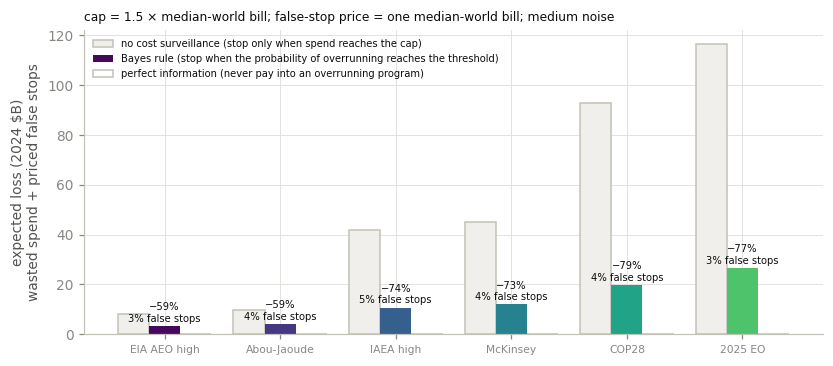

In [7]:
h = p20[(p20["sigma"] == 0.3) & (p20["mult"] == 1.5) & (p20["rho"] == 1.0)].set_index("schedule").reindex(S)
fig, ax = plt.subplots(figsize=(ps.W2 * 0.85, 3.4))
x = np.arange(len(S)); wdt = 0.27
ax.bar(x - wdt, h["risk_ledger_only_B"], wdt, color=ps.NEUTRAL, edgecolor=ps.EDGE_C, label="no cost surveillance (stop only when spend reaches the cap)")
ax.bar(x, h["risk_B"], wdt, color=[ps.SCHED_C[s] for s in S], label="Bayes rule (stop when the probability of overrunning reaches the threshold)")
ax.bar(x + wdt, np.zeros(len(S)), wdt, color="white", edgecolor=ps.EDGE_C, label="perfect information (never pay into an overrunning program)")
for i, s in enumerate(S):
    ax.text(i, h.loc[s, "risk_B"] + 1, f"−{h.loc[s, 'frac_recovered']*100:.0f}%\n{h.loc[s, 'false_stop_rate']*100:.0f}% false stops",
            ha="center", va="bottom", fontsize=6.5, color=ps.INK)
ax.set_xticks(x, [NAME[s] for s in S], fontsize=7)
ax.set_ylabel("expected loss (2024 $B)\nwasted spend + priced false stops")
ax.legend(fontsize=6.5, frameon=False, loc="upper left")
ax.set_title("cap = 1.5 × median-world bill; false-stop price = one median-world bill; medium noise", fontsize=8, loc="left")
fig.tight_layout(); plt.show()


### The frontier plots

Each panel is one program. The **x-axis is the price of a false stop in dollars**
(bottom) and as a multiple of that program's median-world bill (top). The **y-axis
is the expected loss** of the best rule at that price. The flat dashed line is "no
surveillance": stop only when spend reaches the cap. The curves are the Bayes rule at
three observation-noise levels; the gap between a curve and the dashed line is the
value of watching costs at that price. The diamond is today's 5% false-alarm rule,
placed at the false-stop price that makes it the Bayes rule — that is how the
"implied price" of the old alarm is read off. The second figure shows the threshold
itself and its false-stop rate against the price, for four caps: the higher the price
of a false stop, the higher the threshold and the fewer the false stops.

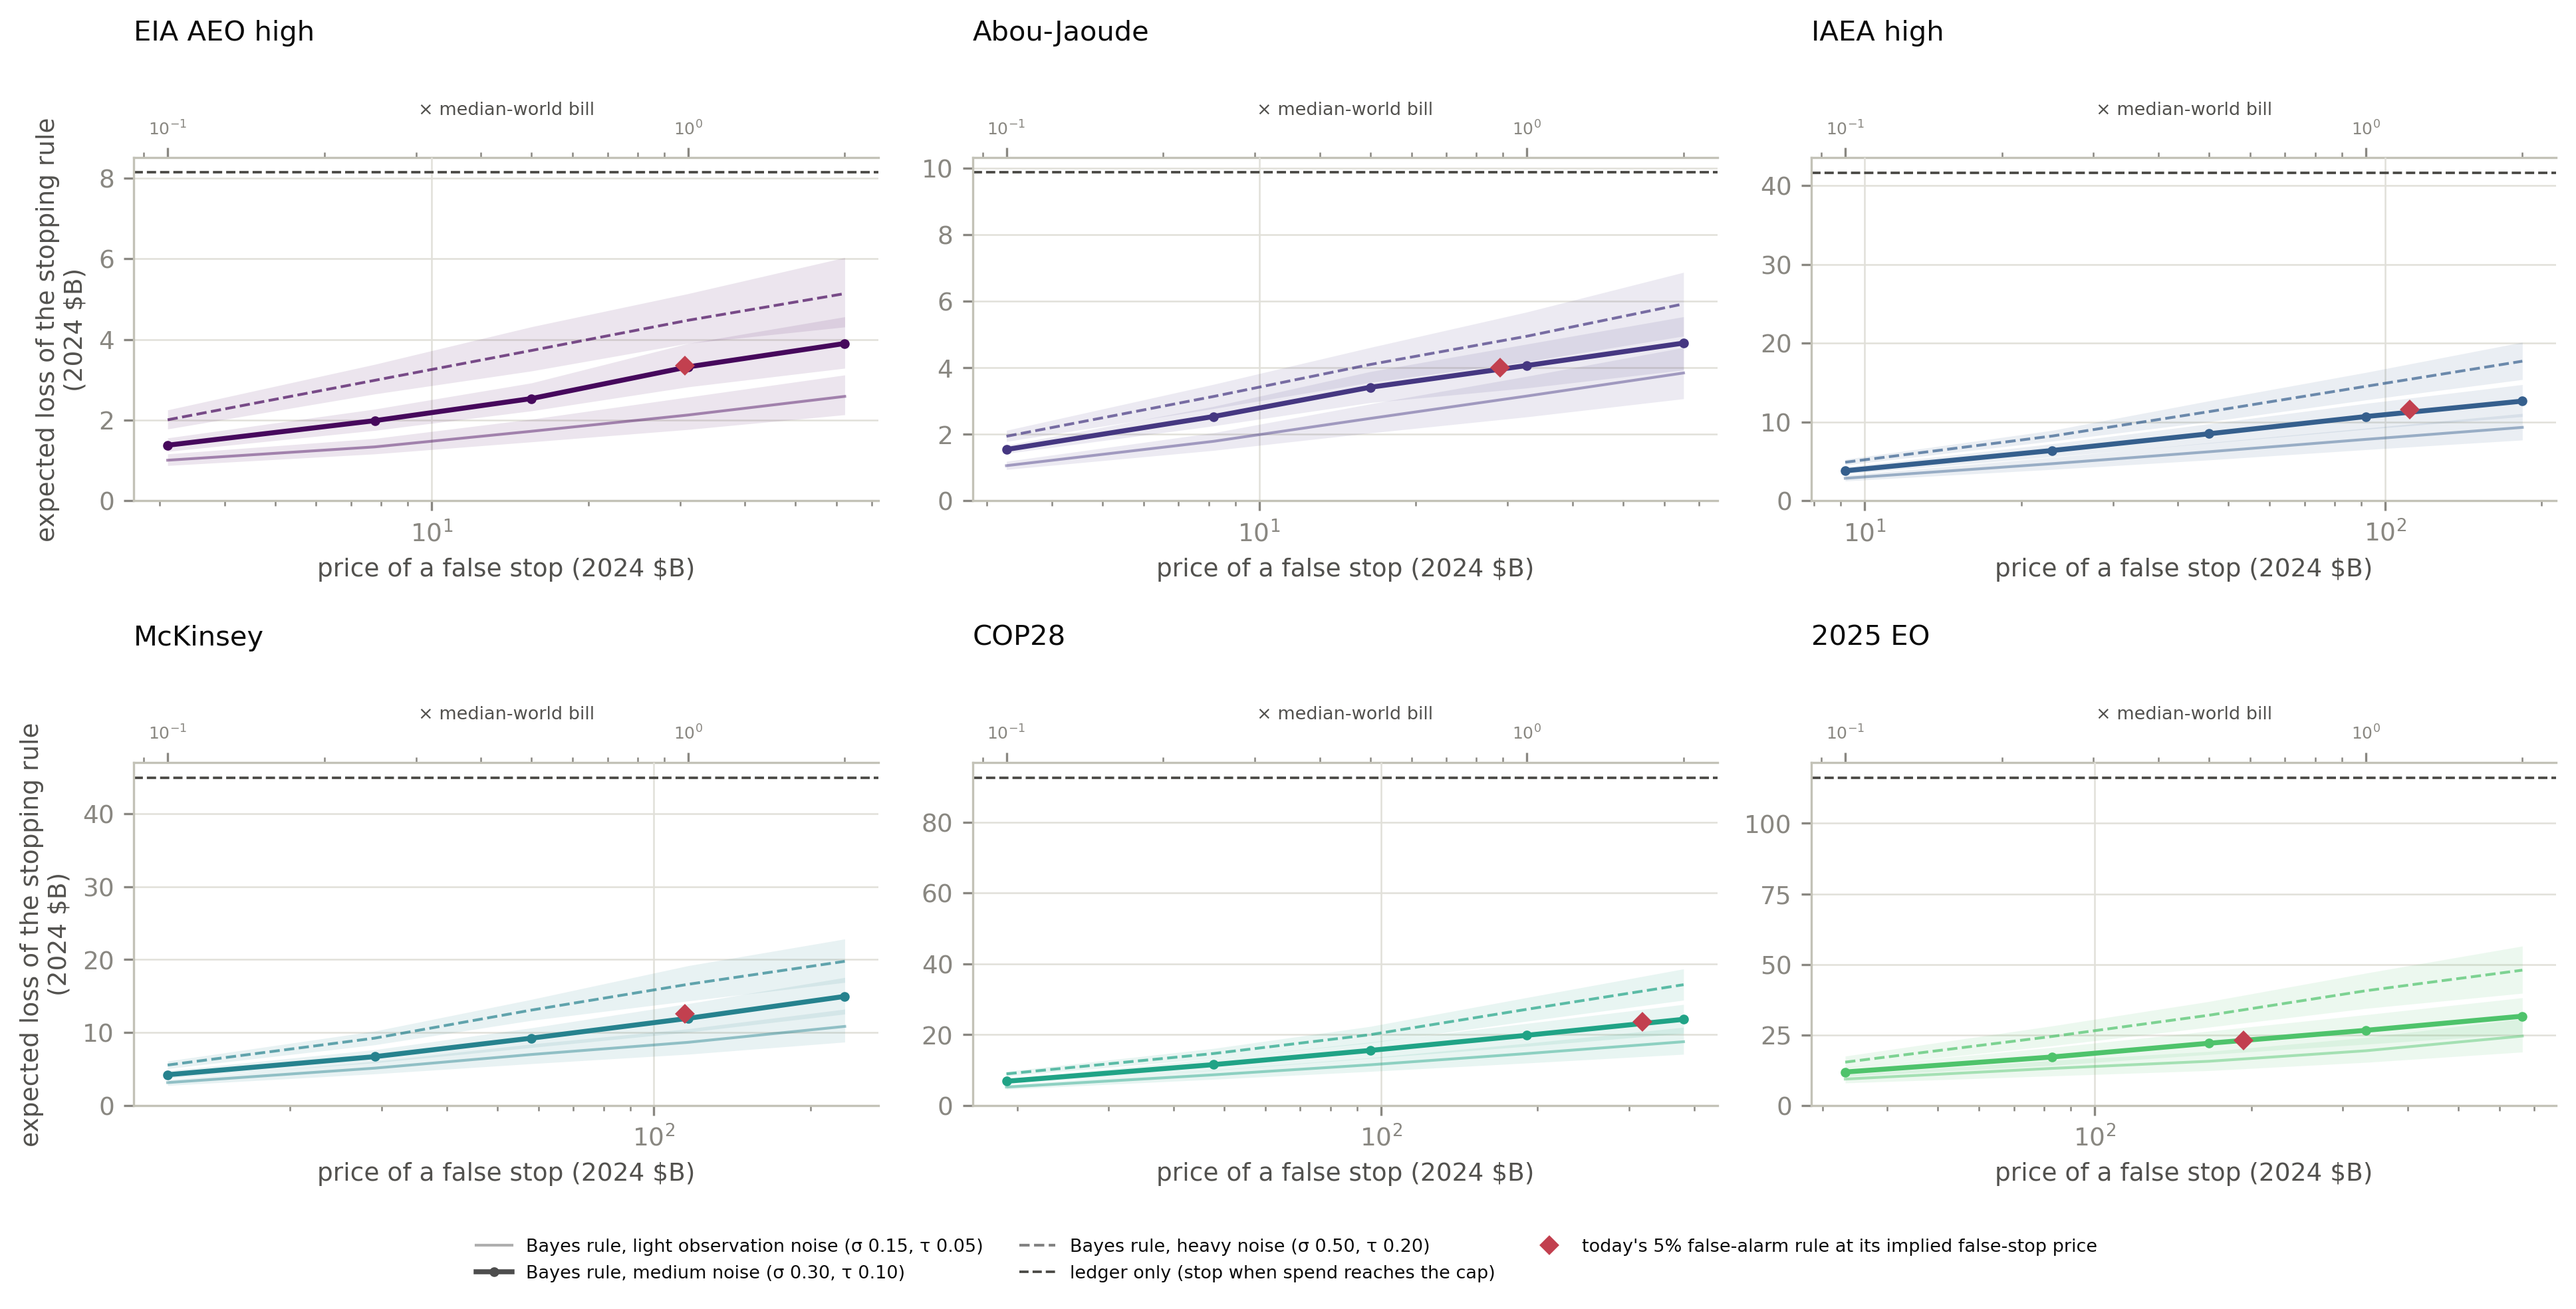

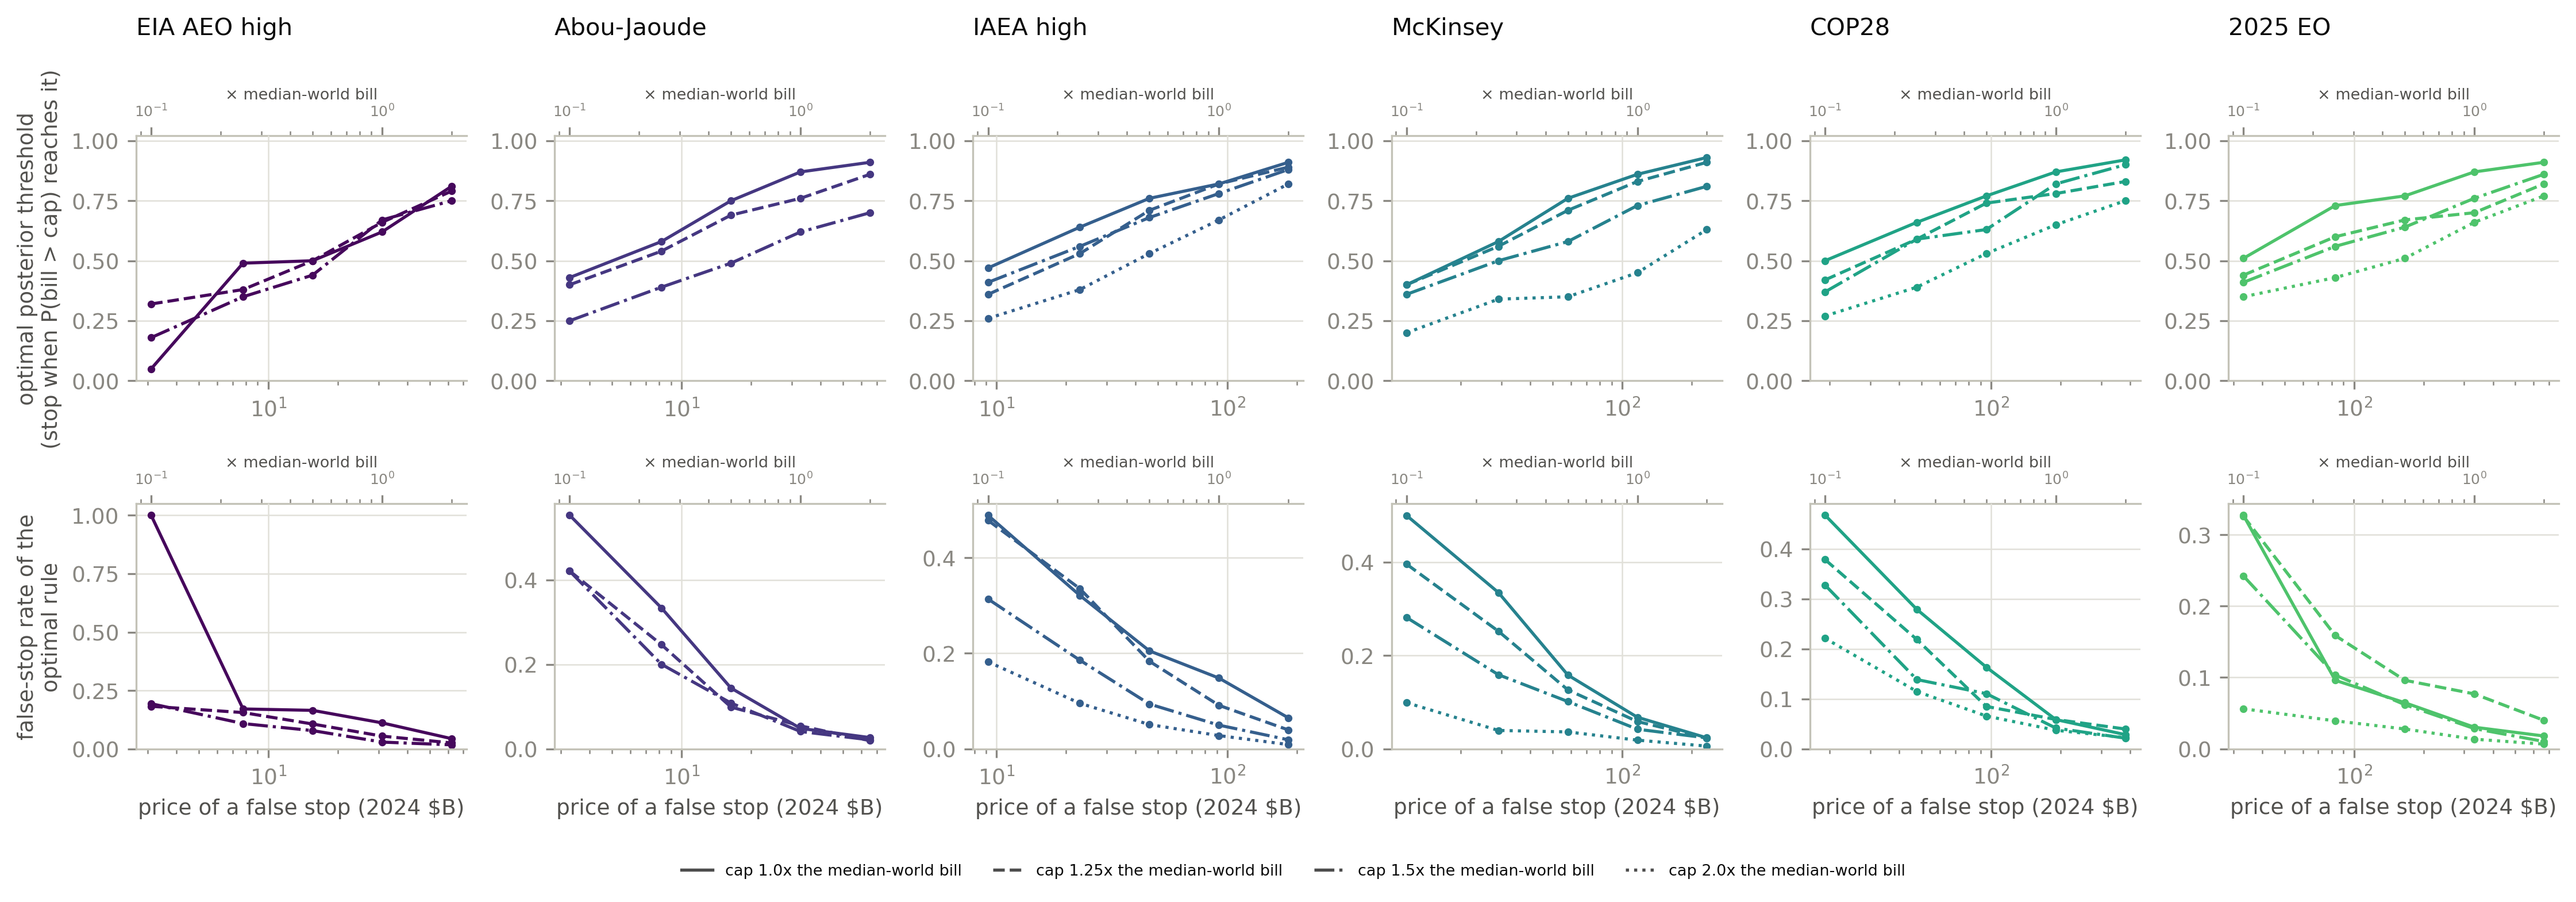

schedule,no surveillance: expected loss (B$),Bayes rule at price 1: threshold,… expected loss (B$),… loss removed,… false-stop rate,… median stop year in overrunning worlds,at price 0.25: threshold,… false-stop rate at 0.25,today's 5% alarm: implied false-stop price (x median-world bill),… in 2024 $B
EIA AEO high (117 GW),8.15,0.67,3.32,0.59,0.03,2041,0.35,0.11,0.98,31
Abou-Jaoude (134 GW),9.87,0.62,4.06,0.59,0.04,2041,0.39,0.20,0.89,29
IAEA high (172 GW),41.64,0.78,10.69,0.74,0.05,2033,0.56,0.19,1.22,112
McKinsey (200 GW),44.94,0.73,11.96,0.73,0.04,2034,0.50,0.16,0.98,115
COP28 (300 GW),92.57,0.82,19.85,0.79,0.04,2033,0.59,0.14,1.67,318
2025 EO (400 GW),116.23,0.76,26.66,0.77,0.03,2033,0.56,0.10,0.58,193



**What the numbers say.** With no surveillance the expected loss from paying into a program that will
overrun the cap is **8.1–116.2 B$**. At a one-to-one price the Bayes rule stops
when the probability of overrunning reaches **0.62–0.82**, removes
**59–79%** of that loss, and stops a good program **3–5%**
of the time. If a false stop is cheap (a quarter of the bill) the threshold falls to
0.35–0.59 and false stops rise to 10–20%. Today's
5% alarm behaves like a Bayes rule whose false-stop price is **0.58–1.67 median-world
bills** (29–318 B$).

**Implications.** (1) The old panel's fixed 5% budget was an unstated price; now it is stated, and it is
about one expected program bill per wrongly killed program — a defensible round number. (2) The value
of cost surveillance is large and holds up at heavy noise. (3) A rule of thumb for the Discussion: at
a 1.5× cap, stop when the probability of overrunning reaches roughly two-thirds to four-fifths; lower
thresholds make sense only if a false stop is cheap. (4) A full optimal-stopping solution (year-varying
threshold, fitted on half the worlds and scored on the other half) beats the constant threshold by
0.1–2.5 B$; the constant threshold is a lower bound on the value of
surveillance and is within the bootstrap interval for 5 of 6 schedules.


In [8]:
show(FIG / "y03_bayes_risk_frontier.png")
show(FIG / "y03b_threshold_vs_rho.png", width=1500)
h20 = p20[(p20["sigma"] == 0.3) & (p20["mult"] == 1.5)]
r1 = h20[h20["rho"] == 1.0].set_index("schedule").reindex(S)
r025 = h20[h20["rho"] == 0.25].set_index("schedule").reindex(S)
c22 = p22[(p22["sigma"] == 0.3) & (p22["mult"] == 1.5)].set_index("schedule").reindex(S)
t = pd.DataFrame({
    "schedule": S,
    "no surveillance: expected loss (B$)": r1["risk_ledger_only_B"].values,
    "Bayes rule at price 1: threshold": r1["pi_bar_opt"].values,
    "… expected loss (B$)": r1["risk_B"].values,
    "… loss removed": r1["frac_recovered"].values,
    "… false-stop rate": r1["false_stop_rate"].values,
    "… median stop year in overrunning worlds": r1["stop_year_med_exceed"].values,
    "at price 0.25: threshold": r025["pi_bar_opt"].values,
    "… false-stop rate at 0.25": r025["false_stop_rate"].values,
    "today's 5% alarm: implied false-stop price (x median-world bill)": c22["rho_implied"].values,
    "… in 2024 $B": (c22["rho_implied"] * pd.Series(P50).reindex(S)).values,
})
table(t, {c: "{:.2f}" for c in t.columns if c not in ("schedule", "… median stop year in overrunning worlds", "… in 2024 $B")}
      | {"… median stop year in overrunning worlds": "{:.0f}", "… in 2024 $B": "{:.0f}"})
lsmc_ok = p21[p21["threshold_not_dominated"]]["schedule"].unique().tolist()
gap = p21.set_index(["schedule", "rho"])["gap_B"]
display(Markdown(f'''
**What the numbers say.** With no surveillance the expected loss from paying into a program that will
overrun the cap is **{rng_(r1["risk_ledger_only_B"])} B$**. At a one-to-one price the Bayes rule stops
when the probability of overrunning reaches **{rng_(r1["pi_bar_opt"], 2)}**, removes
**{rng_(r1["frac_recovered"] * 100, 0)}%** of that loss, and stops a good program **{rng_(r1["false_stop_rate"] * 100, 0)}%**
of the time. If a false stop is cheap (a quarter of the bill) the threshold falls to
{rng_(r025["pi_bar_opt"], 2)} and false stops rise to {rng_(r025["false_stop_rate"] * 100, 0)}%. Today's
5% alarm behaves like a Bayes rule whose false-stop price is **{rng_(c22["rho_implied"], 2)} median-world
bills** ({rng_(c22["rho_implied"] * pd.Series(P50).reindex(S), 0)} B$).

**Implications.** (1) The old panel's fixed 5% budget was an unstated price; now it is stated, and it is
about one expected program bill per wrongly killed program — a defensible round number. (2) The value
of cost surveillance is large and holds up at heavy noise. (3) A rule of thumb for the Discussion: at
a 1.5× cap, stop when the probability of overrunning reaches roughly two-thirds to four-fifths; lower
thresholds make sense only if a false stop is cheap. (4) A full optimal-stopping solution (year-varying
threshold, fitted on half the worlds and scored on the other half) beats the constant threshold by
{gap.abs().min():.1f}–{gap.abs().max():.1f} B$; the constant threshold is a lower bound on the value of
surveillance and is within the bootstrap interval for {len(lsmc_ok)} of 6 schedules.
'''))


## 5. Result C — when demonstration grants can end

**The question.** The statute caps the tax credit (50% today; 60% as the registered
outer case). In build years where a world's required rate is above the cap, the
paper assumes grants cover the excess for the first units — the demonstration
window. The old Figure 6 assumed that window runs through 2035. When *should* it end?

**What the grants buy, and what they cannot.** A world **graduates** when no later
build year needs an above-cap rate; from then on the capped credit alone carries it.
In a world that never graduates within the horizon, the requirement stays above the
cap in the last build year, so once grants stop the credit alone fails, whenever
they stop. Two errors again:

- **Ending too early**: worlds that would have graduated a few years later are cut
  off while they still need above-cap support. The credit alone fails them.
- **Ending too late**: grants keep flowing into worlds that will never graduate.
  Those dollars buy no durable outcome, because those worlds fail anyway when the
  grants end.

So the question is not "when have worlds graduated" (stopping grants in a graduated
world saves nothing: it needs no above-cap support) but "how long to keep paying into
worlds that will not graduate, for the sake of the ones that still will".

### Why the returns diminish: graduation years are bimodal

The figure below is drawn from the per-world table: for each schedule, the share of
cost worlds by the last build year in which they need an above-cap rate, at the 60%
ceiling. Grey bars on the right are worlds still above the cap in the last build year
(never graduate within the horizon); the leftmost bar is worlds that never need a
grant at all.

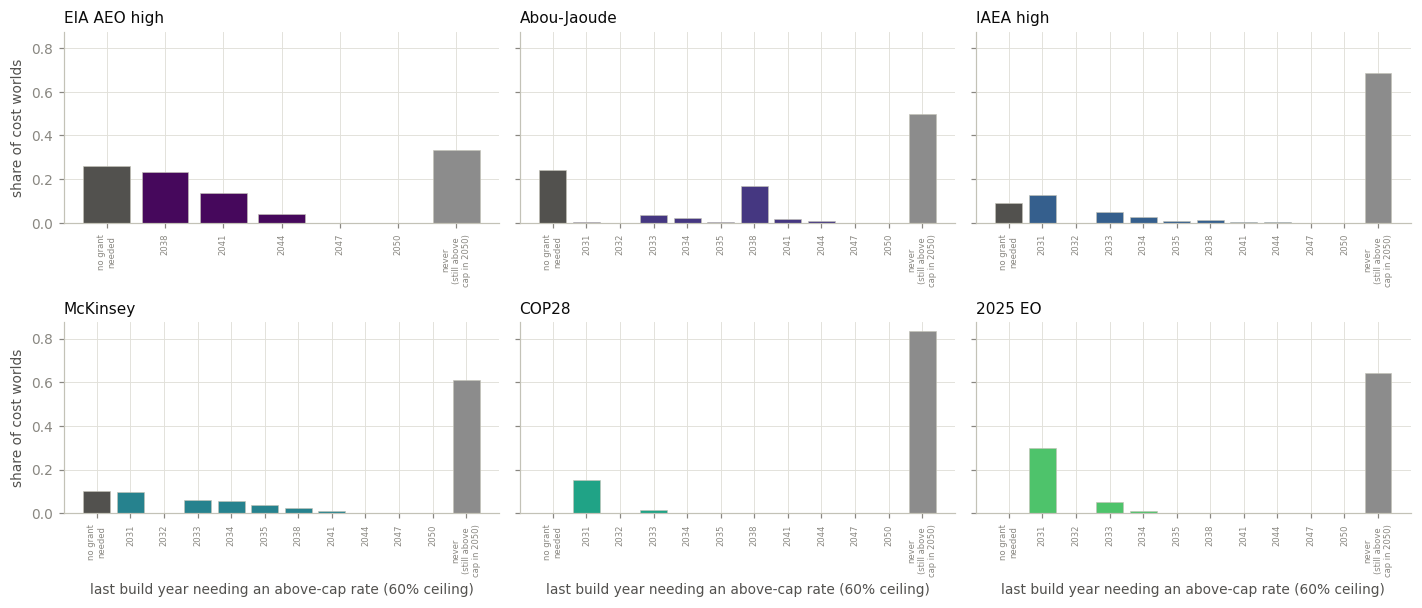


**Reading it.** Worlds either graduate early or not at all. Among worlds that ever need a grant and do
graduate, **90–100%** have graduated by 2038 in the five schedules that build
from 2031 (EIA builds from 2038). Meanwhile **33–83%** of all worlds never graduate
within the horizon. Every year the window is extended past the graduating cluster, almost all of the
added grant money goes into the grey bar.


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(ps.W3, 5.6), sharey=True)
GR = {}
for ax, ab in zip(axes.flat, S):
    g = p30[(p30["schedule"] == ab) & (p30["cap"] == 0.6) & (p30["cut"] == "reg")]
    ly = g["last_above_year"].to_numpy(); never = g["never_within_horizon"].to_numpy()
    ts = sorted(p31[(p31["schedule"] == ab)]["T"].unique())
    shares = [(ly == 0).mean()] + [((ly == t) & ~never).mean() for t in ts] + [never.mean()]
    labels = ["no grant\nneeded"] + [str(t) for t in ts] + ["never\n(still above\ncap in 2050)"]
    colors = [ps.MUTED] + [ps.SCHED_C[ab]] * len(ts) + ["0.55"]
    xs = np.arange(len(shares))
    ax.bar(xs, shares, color=colors, edgecolor=ps.EDGE_C, lw=0.4)
    ax.set_xticks(xs, labels, fontsize=5.5, rotation=90)
    ax.set_title(ps.SCHED_SHORT[ab])
    GR[ab] = dict(ly=ly, never=never, ts=np.array(ts))
for ax in axes[:, 0]:
    ax.set_ylabel("share of cost worlds")
for ax in axes[1, :]:
    ax.set_xlabel("last build year needing an above-cap rate (60% ceiling)")
fig.tight_layout(); plt.show()
never_share = pd.Series({ab: GR[ab]["never"].mean() for ab in S})
early = pd.Series({ab: (((GR[ab]["ly"] > 0) & (GR[ab]["ly"] <= 2038)) & ~GR[ab]["never"]).sum()
                   / max(((GR[ab]["ly"] > 0) & ~GR[ab]["never"]).sum(), 1) for ab in S})
display(Markdown(f'''
**Reading it.** Worlds either graduate early or not at all. Among worlds that ever need a grant and do
graduate, **{rng_(early.drop("eia") * 100, 0)}%** have graduated by 2038 in the five schedules that build
from 2031 (EIA builds from 2038). Meanwhile **{rng_(never_share * 100, 0)}%** of all worlds never graduate
within the horizon. Every year the window is extended past the graduating cluster, almost all of the
added grant money goes into the grey bar.
'''))


### The frontier, and the two costs the window year trades off

**The frontier plot (first figure).** For each candidate window end (labelled by
year along the curve), the x-axis is the expected grant cost of a window ending in
that year and the y-axis is the share of cost worlds covered — no above-cap need
after the window. The curve rises steeply through the early 2030s, flattens (more
grant dollars, almost no more coverage), and jumps to 1.0 at 2050 only because a
window through 2050 is the whole program.

**The decomposition (second figure, drawn here).** For each schedule, the expected
grant cost rises with the window end, while the expected cost of cutting off worlds
that would have graduated later — priced at one median-world bill per cut-off
world — falls. Their sum is the expected loss of ending grants in that year; the
optimum is where the sum is smallest. This is the "Bayes window" the paper's Figure 6
now carries.

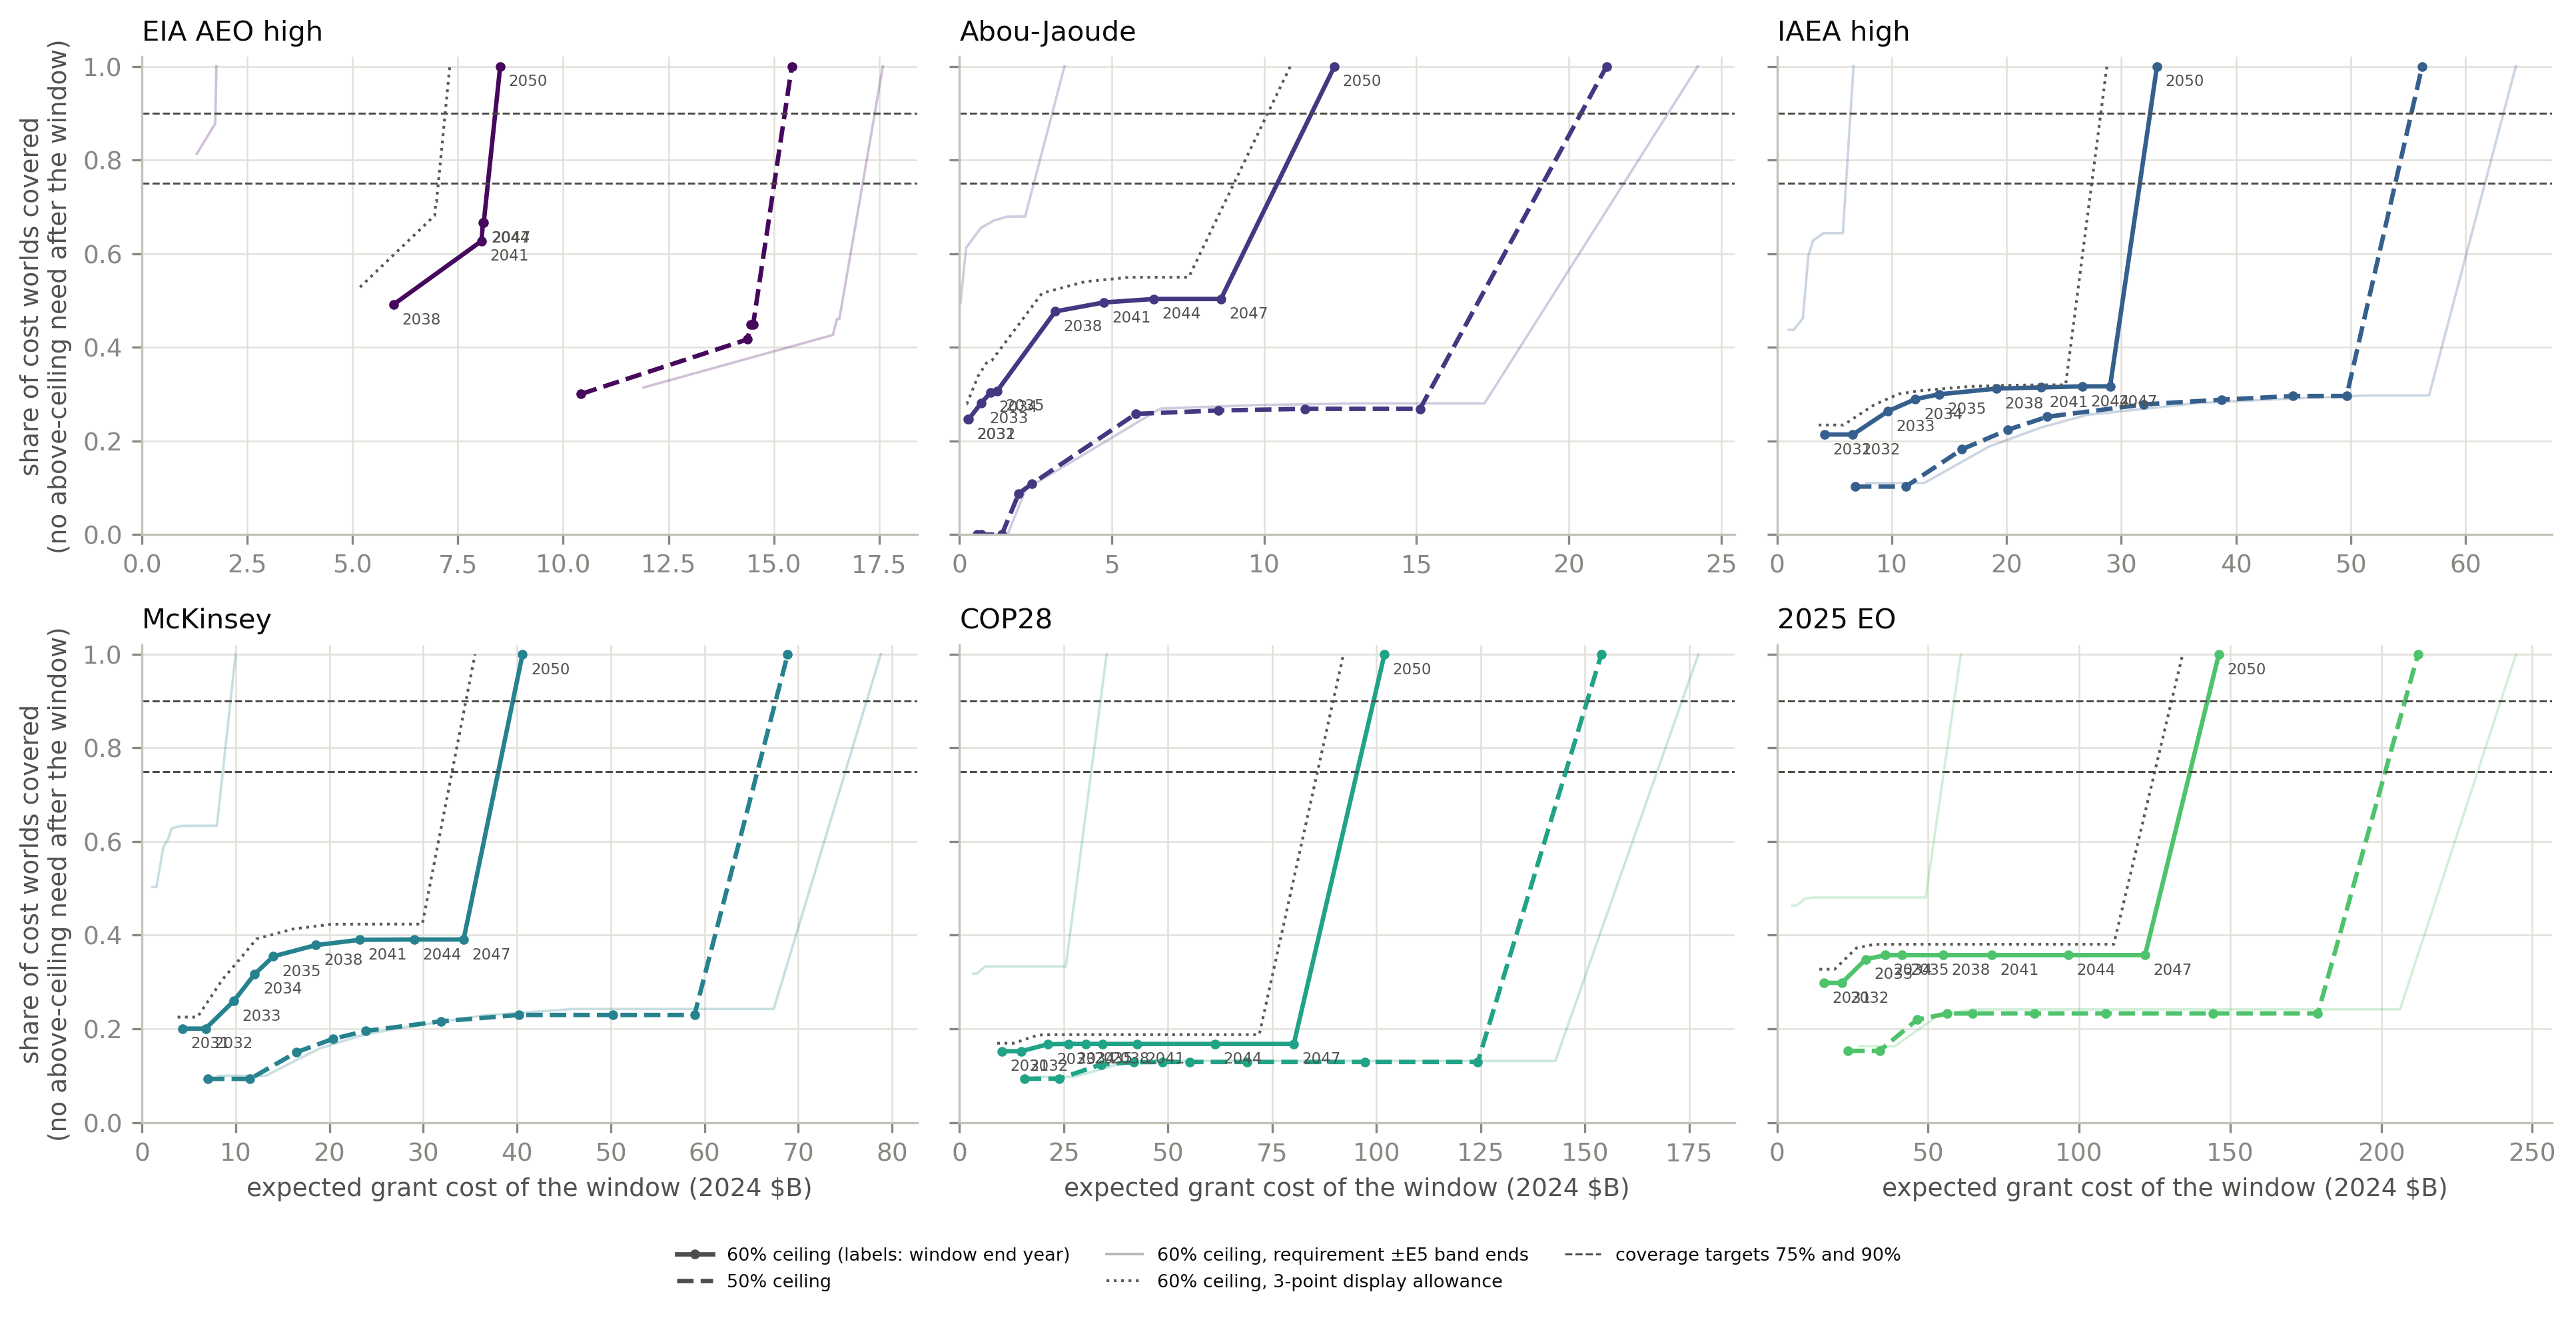

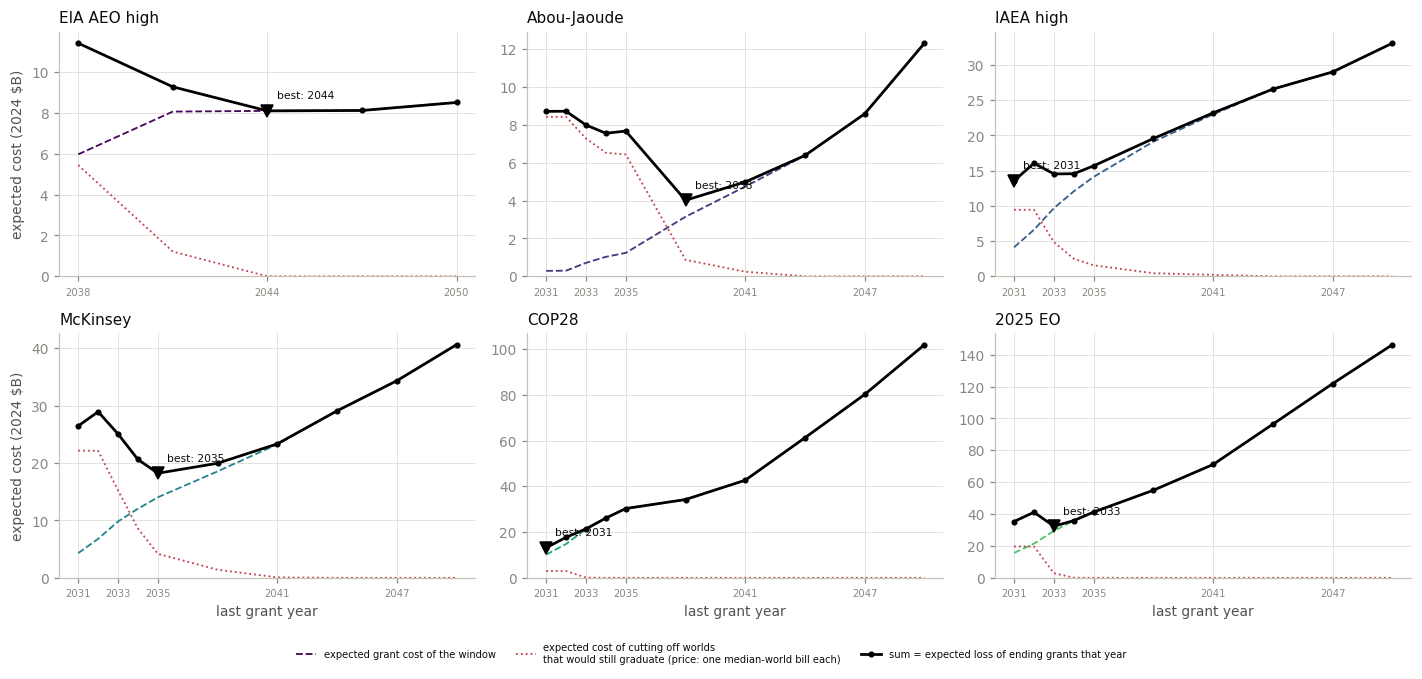

*The optimum drawn here reproduces the analysis table's Bayes window in every schedule.*

In [10]:
show(FIG / "y04_cutoff_frontier.png")
fig, axes = plt.subplots(2, 3, figsize=(ps.W3, 5.8))
PICK = {}
for ax, ab in zip(axes.flat, S):
    f = p31[(p31["schedule"] == ab) & (p31["cap"] == 0.6) & (p31["cut"] == "reg") & (p31["band"] == "base")].sort_values("T")
    ts = f["T"].to_numpy(); G = f["grant_mean_B"].to_numpy()
    ly, never = GR[ab]["ly"], GR[ab]["never"]
    cut = np.array([((ly > T) & ~never).mean() for T in ts]) * P50[ab]
    tot = G + cut
    j = int(np.argmin(tot)); PICK[ab] = int(ts[j])
    ax.plot(ts, G, color=ps.SCHED_C[ab], lw=1.2, ls="--", label="expected grant cost of the window")
    ax.plot(ts, cut, color=ps.ACCENT["red"], lw=1.2, ls=":", label="expected cost of cutting off worlds\nthat would still graduate (price: one median-world bill each)")
    ax.plot(ts, tot, color="k", lw=1.8, marker="o", ms=3, label="sum = expected loss of ending grants that year")
    ax.plot([ts[j]], [tot[j]], marker="v", ms=8, color="k")
    ax.annotate(f"best: {ts[j]}", (ts[j], tot[j]), textcoords="offset points", xytext=(6, 8), fontsize=7)
    ax.set_title(ps.SCHED_SHORT[ab]); ax.set_ylim(0, None)
    ax.set_xticks(ts[::2]); ax.tick_params(axis="x", labelsize=6.5)
for ax in axes[:, 0]:
    ax.set_ylabel("expected cost (2024 $B)")
for ax in axes[1, :]:
    ax.set_xlabel("last grant year")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.tight_layout()
fig.legend(handles, labels, ncol=3, fontsize=6.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.0))
plt.show()
hb = p34[(p34["rule"] == "bayes") & (p34["param"] == 1.0) & (p34["cap"] == 0.6) & (p34["cut"] == "reg") & (p34["band"] == "base")].set_index("schedule").reindex(S)
assert all(PICK[ab] == int(hb.loc[ab, "T_pick"]) for ab in S), (PICK, hb["T_pick"].to_dict())
display(Markdown("*The optimum drawn here reproduces the analysis table's Bayes window in every schedule.*"))


### How stable is the year, and what the paper carries

The optimum depends on the price of a cut-off world. The figure from the analysis
shows the expected loss by last grant year for five prices (top; the bold line is a
price of one median-world bill) and the optimal year against the price in dollars
(bottom), with the requirement-band ends faint. Two horizontal lines give a
price-free companion: the shortest window that covers 75% and 90% of the worlds that
ever graduate after needing grants.

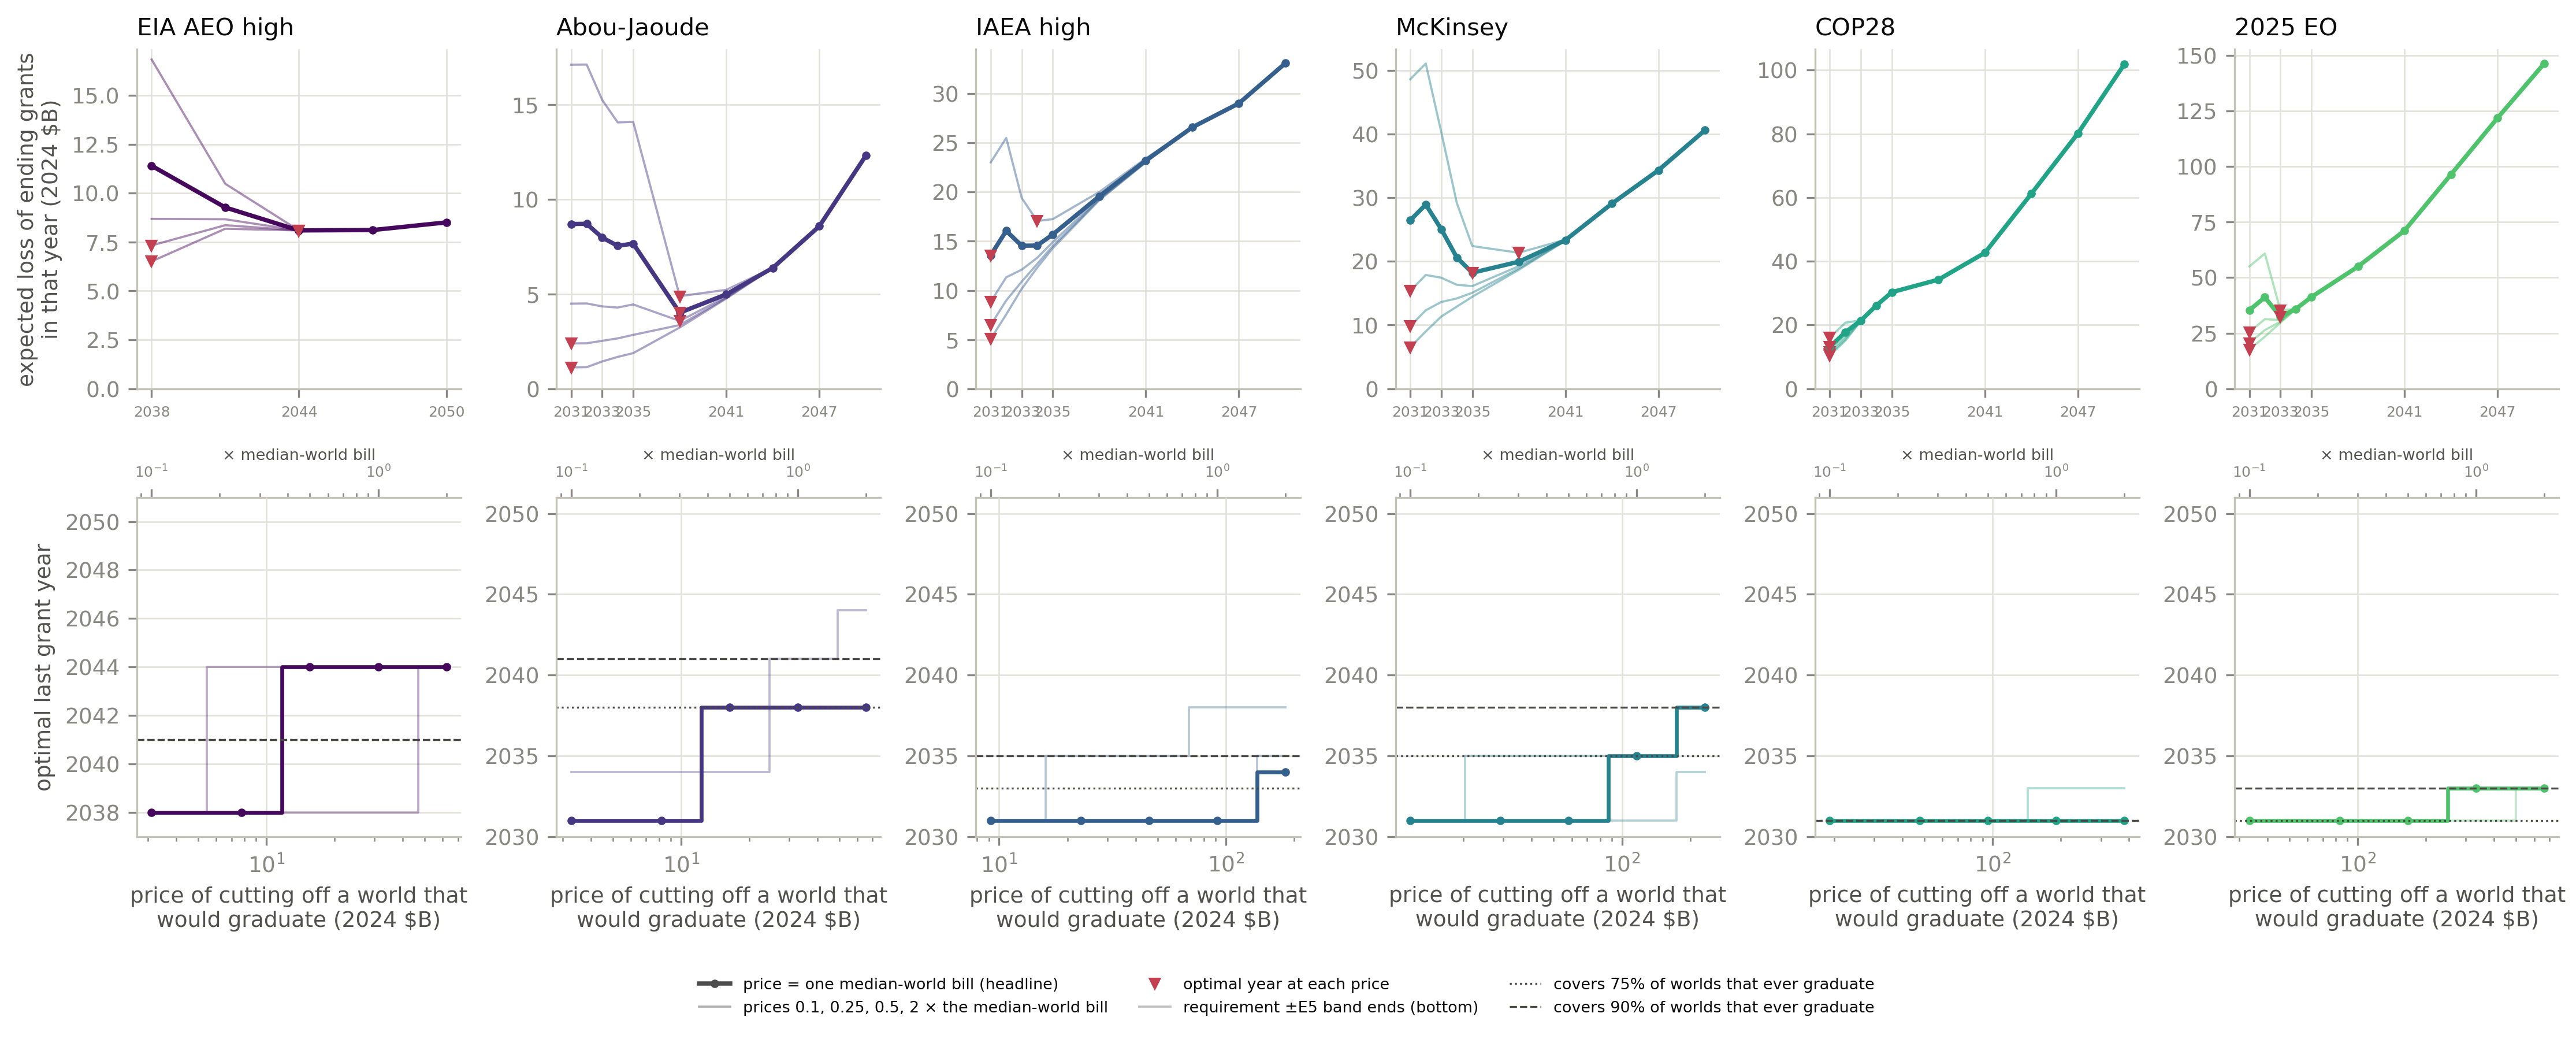

schedule,first build year,Bayes window at price 1 (last grant year),… range as the price runs 0.1–2 x,… moves across the requirement band?,… expected grant cost (B$),… share of worlds cut off,covers 75% of worlds that ever graduate,covers 90% of worlds that ever graduate,share of worlds that ever graduate after needing grants
EIA AEO high (117 GW),2038,2044,2038-2044,yes,8.1,0.000,2041,2041,0.41
Abou-Jaoude (134 GW),2031,2038,2031-2038,yes,3.1,0.027,2038,2041,0.26
IAEA high (172 GW),2031,2031,2031-2034,yes,4.1,0.103,2033,2035,0.23
McKinsey (200 GW),2031,2035,2031-2038,yes,14.0,0.036,2035,2038,0.29
COP28 (300 GW),2031,2031,2031-2031,yes,10.1,0.015,2031,2031,0.17
2025 EO (400 GW),2031,2033,2031-2033,yes,29.4,0.009,2031,2033,0.36



**What the numbers say.** At a price of one median-world bill the window ends in
**EIA AEO high 2044, Abou-Jaoude 2038, IAEA high 2031, McKinsey 2035, COP28 2031, 2025 EO 2033**. The two largest programs finish
learning by 2033, the mid-size programs by the mid-2030s, and the small ones later (EIA builds only
from 2038). The optimum moves with the price in 5 of 6 schedules and across the requirement band
in all six (disclosed, never averaged); the price-free companion is stable and agrees with the Bayes
year within one build step in 5 of 6 schedules.

**Implication.** The paper does not carry these years (Ethan, 2026-09-10): because graduation is
all but complete by 2038 in every schedule, Figure 6 carries one common window end, 2038, and Table 2
reports the never-feasible share, the share feasible by 2038 and the last graduation year; the
per-schedule years stay here and in SF56/ST19. For the text: the demonstration window
should last until the worlds that can graduate have done so — the early-to-mid 2030s for the large
programs, about 2038 to 2044 for the small ones; beyond that, grants are a standing subsidy to worlds
the statute cannot carry. Whatever the year, 33–83% of worlds remain uncovered:
the window cannot rescue the statutory wall, it only decides how long to pay into the worlds behind it.


In [11]:
show(FIG / "y06_window_decision.png", width=1500)
hq = p34[(p34["rule"] == "cond_quantile") & (p34["cap"] == 0.6) & (p34["cut"] == "reg") & (p34["band"] == "base")]
q75 = hq[hq["param"] == 0.75].set_index("schedule").reindex(S); q90 = hq[hq["param"] == 0.9].set_index("schedule").reindex(S)
t = pd.DataFrame({
    "schedule": S, "first build year": hb["first_build_year"].values,
    "Bayes window at price 1 (last grant year)": hb["T_pick"].values,
    "… range as the price runs 0.1–2 x": hb["T_range_over_rho"].values,
    "… moves across the requirement band?": hb["band_range_flag"].map({True: "yes", False: "no"}).values,
    "… expected grant cost (B$)": hb["grant_mean_B"].values,
    "… share of worlds cut off": hb["cut_share"].values,
    "covers 75% of worlds that ever graduate": q75["T_pick"].values,
    "covers 90% of worlds that ever graduate": q90["T_pick"].values,
    "share of worlds that ever graduate after needing grants": q90["share_ever_graduate"].values,
})
table(t, {"… expected grant cost (B$)": "{:.1f}", "… share of worlds cut off": "{:.3f}",
          "share of worlds that ever graduate after needing grants": "{:.2f}"})
agree = [s for s in S if abs(int(hb.loc[s, "T_pick"]) - int(q90.loc[s, "T_pick"])) <= 3]
n_move = int((hb["T_range_over_rho"].str.split("-").str[0] != hb["T_range_over_rho"].str.split("-").str[1]).sum())
display(Markdown(f'''
**What the numbers say.** At a price of one median-world bill the window ends in
**{", ".join(f"{NAME[s]} {int(hb.loc[s, 'T_pick'])}" for s in S)}**. The two largest programs finish
learning by 2033, the mid-size programs by the mid-2030s, and the small ones later (EIA builds only
from 2038). The optimum moves with the price in {n_move} of 6 schedules and across the requirement band
in all six (disclosed, never averaged); the price-free companion is stable and agrees with the Bayes
year within one build step in {len(agree)} of 6 schedules.

**Implication.** The paper does not carry these years (Ethan, 2026-09-10): because graduation is
all but complete by 2038 in every schedule, Figure 6 carries one common window end, 2038, and Table 2
reports the never-feasible share, the share feasible by 2038 and the last graduation year; the
per-schedule years stay here and in SF56/ST19. For the text: the demonstration window
should last until the worlds that can graduate have done so — the early-to-mid 2030s for the large
programs, about 2038 to 2044 for the small ones; beyond that, grants are a standing subsidy to worlds
the statute cannot carry. Whatever the year, {rng_(never_share * 100, 0)}% of worlds remain uncovered:
the window cannot rescue the statutory wall, it only decides how long to pay into the worlds behind it.
'''))


### The learning version: an abandonment trigger

The year above is fixed in advance. With observed costs the government can instead
act on evidence: stop grants when the probability that *this* world will never
become credit-feasible reaches a threshold. It is the twin of the stopping rule in
section 4 — same structure, a different event (never-feasible instead of
over-the-cap). Grants paid into a never-feasible world are wasted; stopping a world
that would have graduated is priced, again in dollars per wrongly abandoned world.

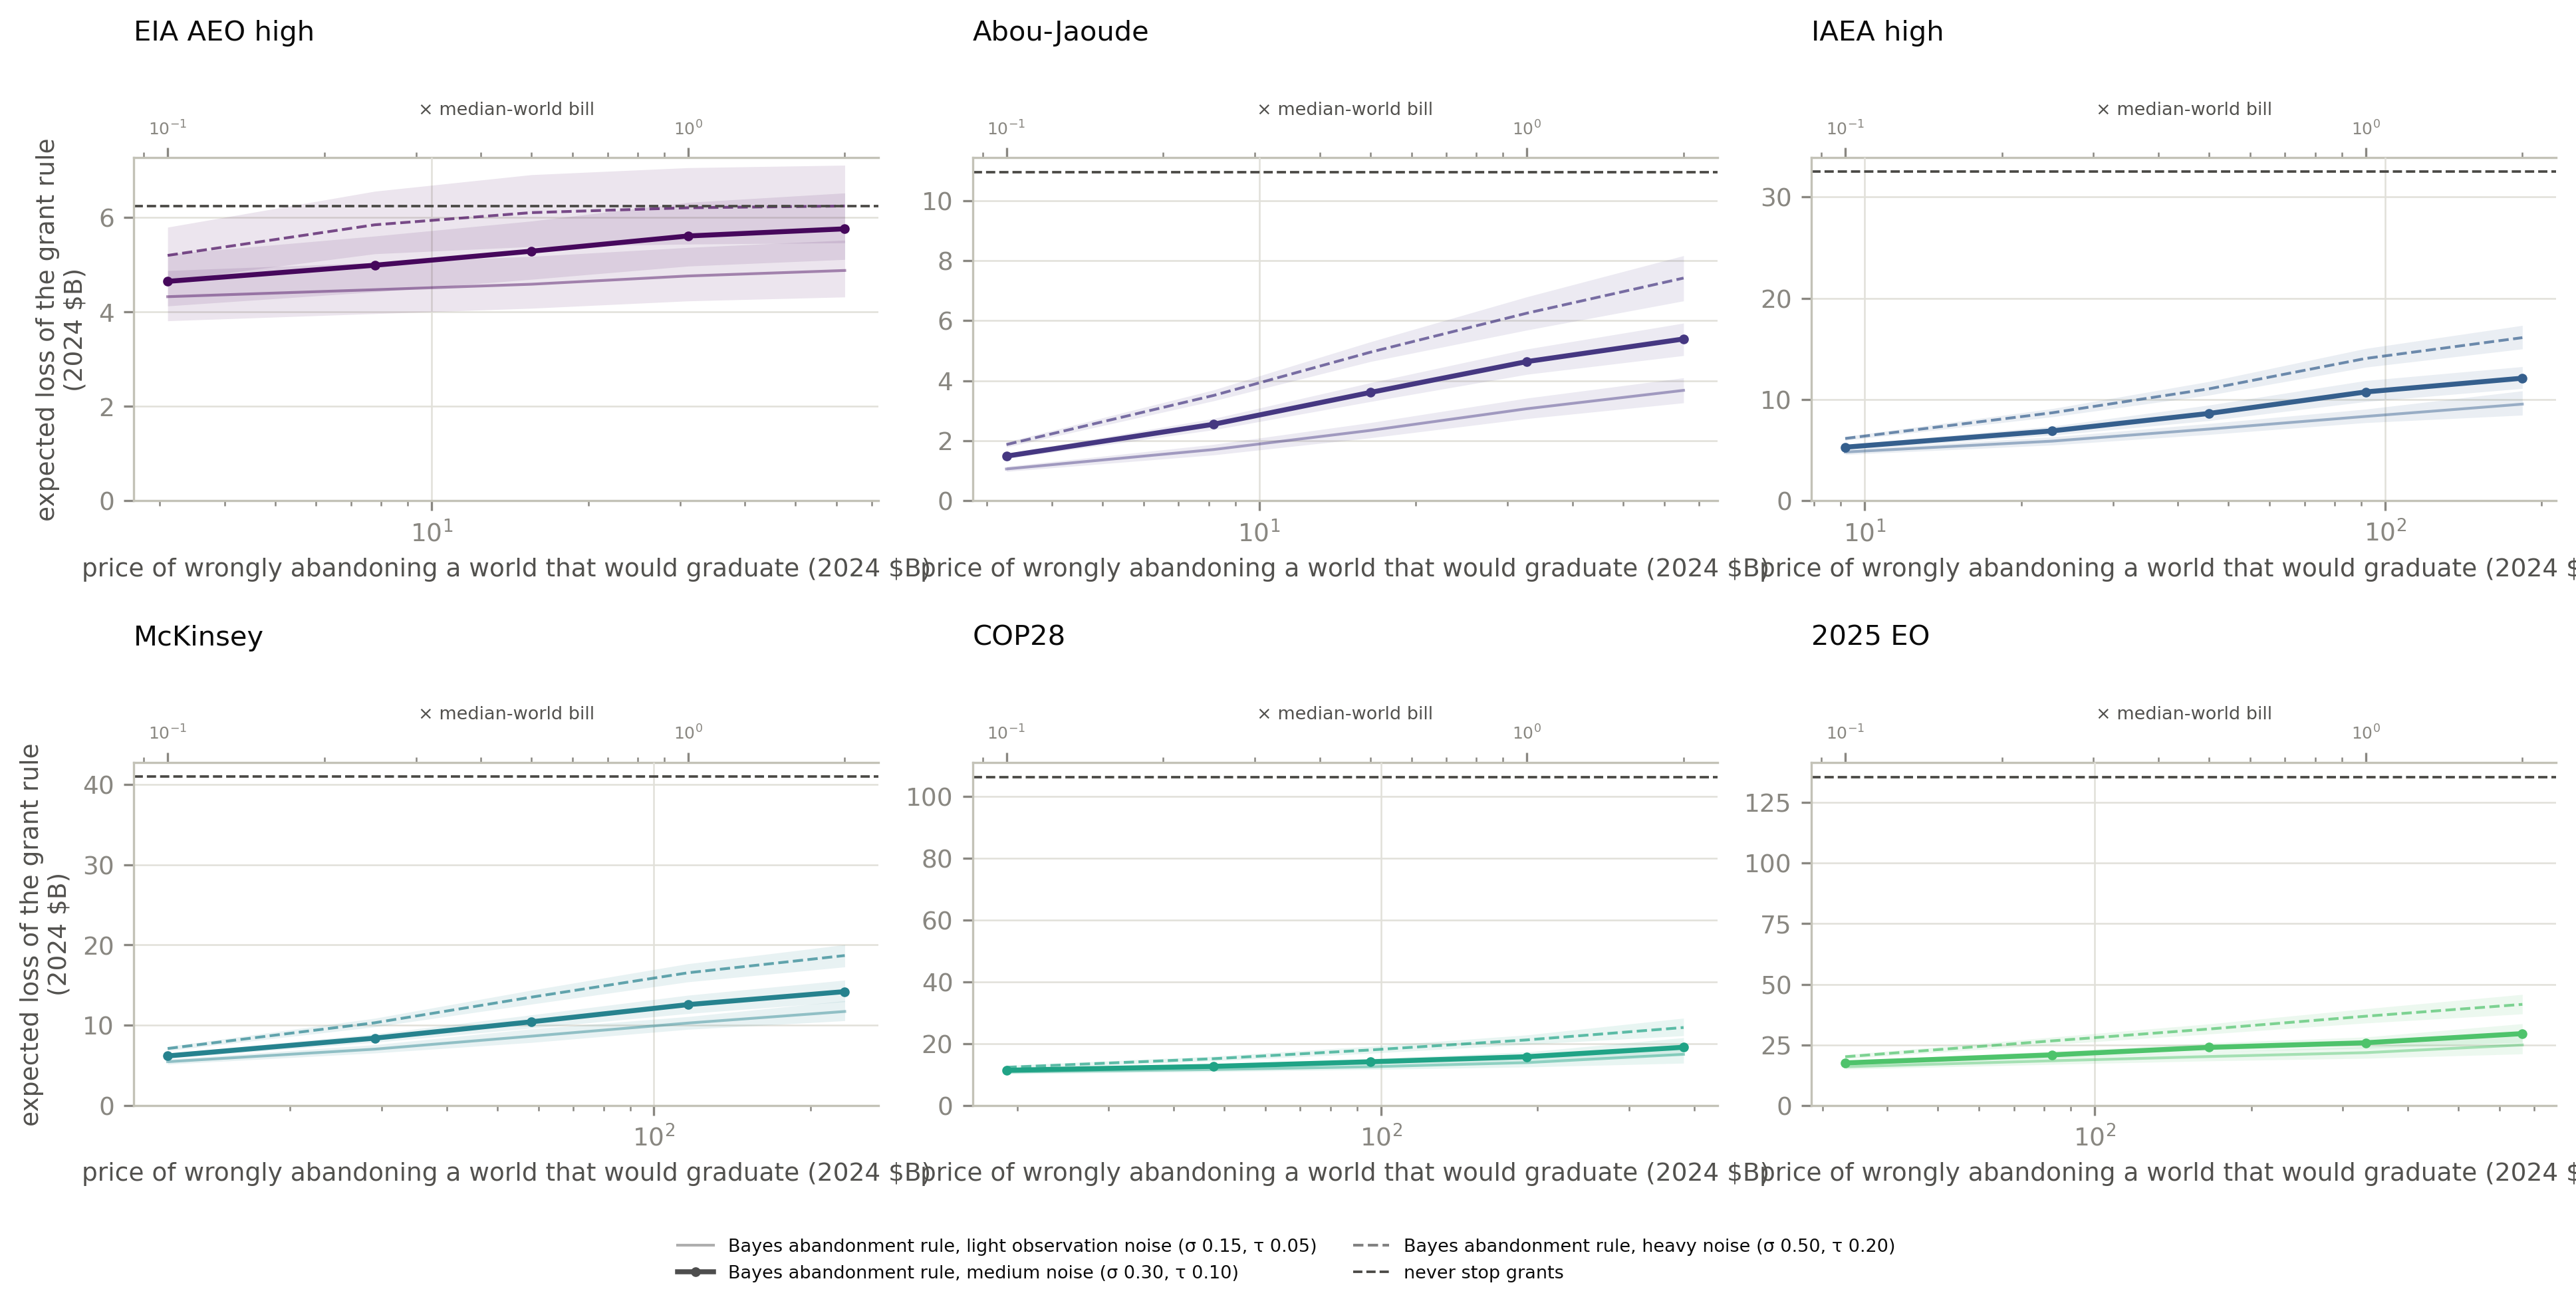

schedule,worlds never credit-feasible (share),expected loss if grants never stop (B$),Bayes trigger at a price of half a median-world bill: threshold,… expected loss (B$),… loss removed,… wrongly abandoned (share of worlds that would graduate),… median abandonment year
EIA AEO high (117 GW),0.31,6.25,0.80,5.29,0.15,0.04,2038
Abou-Jaoude (134 GW),0.44,10.94,0.80,3.61,0.67,0.15,2038
IAEA high (172 GW),0.67,32.51,0.80,8.62,0.73,0.22,2031
McKinsey (200 GW),0.62,40.97,0.85,10.44,0.75,0.13,2032
COP28 (300 GW),0.83,106.17,0.90,14.15,0.87,0.19,2031
2025 EO (400 GW),0.64,135.53,0.95,24.00,0.82,0.03,2033



**What the numbers say.** At half a median-world bill per wrongly abandoned world, the trigger removes
**15–87%** of the grant loss, abandoning never-feasible worlds around
**2031–2038** while wrongly abandoning
3–22% of the worlds that would have graduated.

**Implication.** The fixed window and the evidence trigger say the same thing from two sides: the data
identify never-feasible worlds within the first few build years, so a commitment horizon in the
early-to-mid 2030s and an observation-triggered exit land in the same place. The paper can present the
window as the commitment device and the trigger as its SI companion.


In [12]:
show(FIG / "y05_abandonment_frontier.png")
h33 = p33[(p33["sigma"] == 0.3) & (p33["cap"] == 0.6) & (p33["cut"] == "reg") & (p33["rho_g"] == 0.5)].set_index("schedule").reindex(S)
t = pd.DataFrame({"schedule": S, "worlds never credit-feasible (share)": h33["share_never_sample"].values,
                  "expected loss if grants never stop (B$)": h33["risk_never_stop_B"].values,
                  "Bayes trigger at a price of half a median-world bill: threshold": h33["beta_opt"].values,
                  "… expected loss (B$)": h33["risk_B"].values, "… loss removed": h33["frac_recovered"].values,
                  "… wrongly abandoned (share of worlds that would graduate)": h33["false_abandon_rate"].values,
                  "… median abandonment year": h33["T_abandon_med"].values})
table(t, {c: "{:.2f}" for c in t.columns if c not in ("schedule", "… median abandonment year")} | {"… median abandonment year": "{:.0f}"})
display(Markdown(f'''
**What the numbers say.** At half a median-world bill per wrongly abandoned world, the trigger removes
**{rng_(h33["frac_recovered"] * 100, 0)}%** of the grant loss, abandoning never-feasible worlds around
**{int(h33["T_abandon_med"].min())}–{int(h33["T_abandon_med"].max())}** while wrongly abandoning
{rng_(h33["false_abandon_rate"] * 100, 0)}% of the worlds that would have graduated.

**Implication.** The fixed window and the evidence trigger say the same thing from two sides: the data
identify never-feasible worlds within the first few build years, so a commitment horizon in the
early-to-mid 2030s and an observation-triggered exit land in the same place. The paper can present the
window as the commitment device and the trigger as its SI companion.
'''))


## 6. The new Figure 6 and what changed in the paper

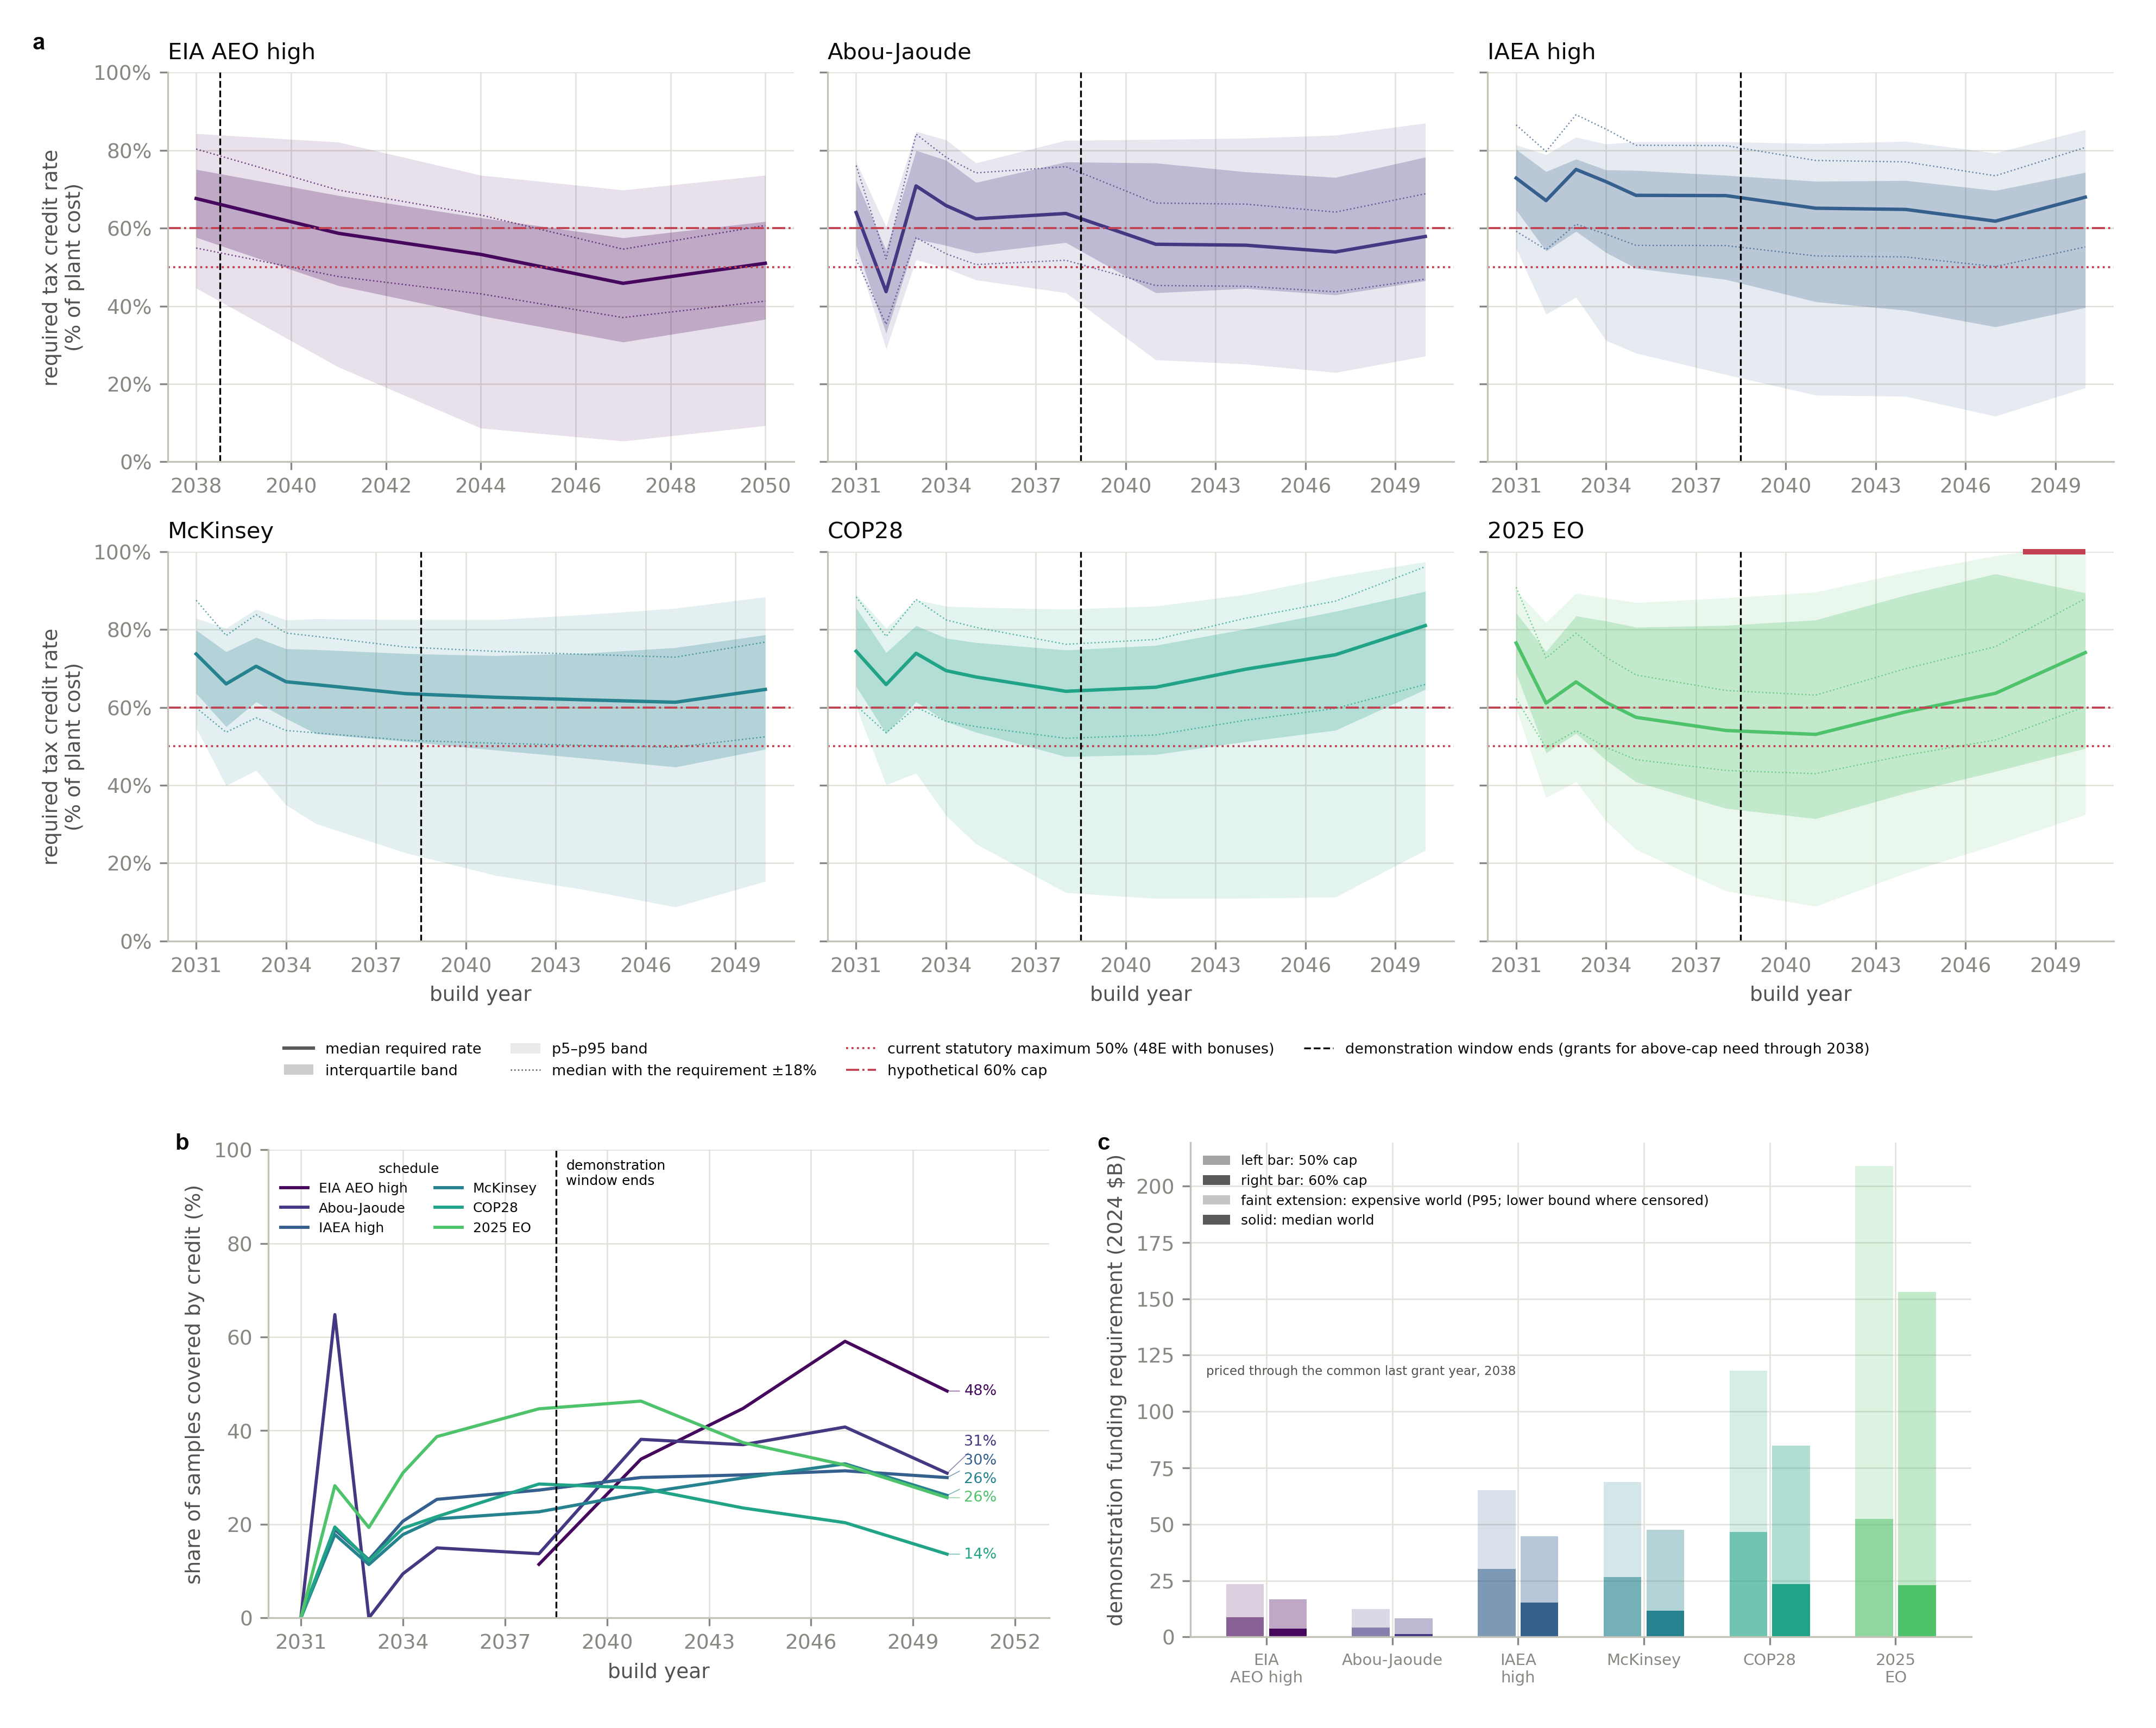


**Figure 6 as it now stands (2026-09-10).** (a) Required statutory credit rates by build year, with
one dashed line at the common demonstration-window end, 2038. (b) The share of samples covered by
the credit at the 50% statutory maximum, by build year; the right-edge label on each curve is the
share covered in the last build year, which is the share of worlds that ever become
credit-feasible. (c) The demonstration funding requirement priced through 2038. Main-text Table 2
(new) gives, per schedule and ceiling, the never-feasible share, the share feasible by 2038, the
share that becomes feasible only after 2038 (at most a few percent outside EIA) and the last year
any world does. The caption
regenerates from the exports.

**Paper-level changes to make (Ethan's call on wording).**
- S3-3: the calibration-limit sentence must be restated — the credit-scale band stays wide, but the
  decision value is largely recovered early; the learning rate, not the required credit, is what
  observation cannot pin down.
- Fig 5: candidate replacement panels are the EVSI curves (y01) and the Bayes-risk frontier (y03);
  today's alarm survives only as the diamond with its implied price.
- S3-4 / Fig 6 / Table 2: one common window end, 2038, for every schedule (Ethan 2026-09-10), chosen
  because graduation is all but complete by 2038 everywhere; Table 2 is the ninth main-text display item; the
  post-window infeasible share ranges in the caption moved; the outline's §10 numbers, display
  budget and the plan need a bump.
- D3: "the cost of finding out" becomes a dollar EVPI with its recovered share, and the stop rule gets
  its explicit price.


In [13]:
show(PF / "Fig6_required_itc_and_menu.png", width=1500)
display(Markdown('''
**Figure 6 as it now stands (2026-09-10).** (a) Required statutory credit rates by build year, with
one dashed line at the common demonstration-window end, 2038. (b) The share of samples covered by
the credit at the 50% statutory maximum, by build year; the right-edge label on each curve is the
share covered in the last build year, which is the share of worlds that ever become
credit-feasible. (c) The demonstration funding requirement priced through 2038. Main-text Table 2
(new) gives, per schedule and ceiling, the never-feasible share, the share feasible by 2038, the
share that becomes feasible only after 2038 (at most a few percent outside EIA) and the last year
any world does. The caption
regenerates from the exports.

**Paper-level changes to make (Ethan's call on wording).**
- S3-3: the calibration-limit sentence must be restated — the credit-scale band stays wide, but the
  decision value is largely recovered early; the learning rate, not the required credit, is what
  observation cannot pin down.
- Fig 5: candidate replacement panels are the EVSI curves (y01) and the Bayes-risk frontier (y03);
  today's alarm survives only as the diamond with its implied price.
- S3-4 / Fig 6 / Table 2: one common window end, 2038, for every schedule (Ethan 2026-09-10), chosen
  because graduation is all but complete by 2038 everywhere; Table 2 is the ninth main-text display item; the
  post-window infeasible share ranges in the caption moved; the outline's §10 numbers, display
  budget and the plan need a bump.
- D3: "the cost of finding out" becomes a dollar EVPI with its recovered share, and the stop rule gets
  its explicit price.
'''))


## 7. Caveats every quoted number carries

- **The observer knows the model.** It holds the paper's own 10,000-world ensemble and
  the exact noise model, so every value of information here is an upper bound on what
  a real government could learn; the truth world is removed from the candidate set
  (leave-one-out) so the bound is not inflated by self-recognition.
- **Costs are observed at construction start**, the stage-3 convention.
- **The dollar loss is a stylization.** The paper's delivery semantics are threshold
  (any shortfall in a year is a failed build); the linear shortfall price makes the
  quantile act optimal and the numbers comparable, and it is stated once.
- **EVPI at 90% coverage is a lower bound**: the worlds above the 90% quantile mostly
  sit on the requirement map's top clamp, where rates are understated (K2).
- **Outlay pricing is fixed-basis** with the ±5% calibration systematic the paper
  already carries; the requirement map carries its ±18% certificate band, and the
  window year moves across it.
- **"Never credit-feasible" means within the horizon.**
- **The price parameters are the reader's**, not ours; the paper reports the sweep and
  shows where its own conventions sit on it.
- **The constant-threshold stopping rule is a lower bound** on the optimal-stopping
  value; the LSMC check shows how much is left.

In [14]:
kills = p90.loc[["K1", "K2", "K3", "K5", "G6", "G7"], ["result", "detail"]].copy()
kills["detail"] = kills["detail"].str.slice(0, 220) + "…"
display(kills)
preds = p90.loc[["P1", "P2", "P3", "P4", "P5"], ["result", "detail"]].copy()
preds["detail"] = preds["detail"].str.slice(0, 220) + "…"
display(Markdown("**Registered predictions, scored as written** (two missed; the misses are the interesting results):"))
display(preds)


,result,detail
name,,
K1,PASS,observation years with leave-one-out q10 ESS <...
K2,DISCLOSED,EVPI quoted as a lower bound (top-knot clamp a...
K3,DISCLOSED,T_alpha quoted as a range where the E5 band en...
K5,DISCLOSED,no cut-off year before the last build year rea...
G6,DISCLOSED,"conformal reference (1.5x cap, mid noise) paid..."
G7,DISCLOSED,threshold-rule risk minus LSMC optimal-stoppin...


**Registered predictions, scored as written** (two missed; the misses are the interesting results):

,result,detail
name,,
P1,MISSED,"dollar EVSI/EVPI at k = K-2, mid noise, alpha ..."
P2,MISSED,"group {lr_smr, boak_smr} EVPPI share of dollar..."
P3,CONFIRMED,"max coverage at T <= 2044, 60% ceiling, regist..."
P4,CONFIRMED,value of early abandonment at rho_g = 0.5 (202...
P5,CONFIRMED,implied false-stop price rho_5% (x median-worl...


## 8. Where everything lives and how to reproduce it

- **Registration and log**: `z-ethan/voi/methods.md` (gates G0–G7, kills K1–K5,
  predictions P1–P5, the v1.1 window addendum, the three post-execution repairs) and
  `status.md` (runs, outcomes, Ethan's rulings).
- **Analysis**: `voi.ipynb`, emitted by `_build_notebook.py`; run with `_run_voi.py`
  on the playground-env kernel (about 40 minutes for the sweep; a cached re-run takes
  under two minutes; `--force` recomputes the cache).
- **Tables**: `exports/p10`–`p35`, verdict `p90_verdict.csv` — the only source paper
  text may quote. **Figures**: `figures/y01`–`y06`. **This notebook**:
  `_build_explainer.py` → `voi_explainer.ipynb`.
- **Reproduction gates**: the requirement map reproduces the paper's five-anchor
  per-world table and both window tables exactly (G0); the observer reproduces the
  paper's frozen uncertainty-width table at every observation and noise level (G1);
  one spot case checks the vectorized weights against a brute-force product (G4a).
- **Paper wiring**: SF54–SF56, ST19 and SN11 in the appendix notebook; Fig 6 and Table 2
  use one common window end, 2038 (`W_COMMON` in the rate-design builder;
  `p36_common_window_table.csv`).

In [15]:
for name in ["G0", "G1", "G2", "G3", "G4", "G4a", "G5"]:
    print(f"{name}: {p90.loc[name, 'result']} — {p90.loc[name, 'detail'][:160]}")


G0: PASS — requirement map reproduces u01_5a (f*, binding year, clamp), u51_5a and u52_5a (both windows) exactly; 30 anchors, E5 and bills from the 5a run; kappa residual 
G1: PASS — re-implemented observer reproduces u10_ci_curves_5a (f* width, learning-rate width, ESS medians) at every k and noise level to the stored rounding
G2: PASS — posterior alpha-rule realized coverage under the model within the cluster-robust 99% band at mid noise, alpha 0.90, every k (self-consistency, not calibration)
G3: PASS — EVSI(k) <= EVPI_{>k} in both losses at every schedule x noise x alpha x k
G4: PASS — EVPPI_j <= EVPI in both losses for every dial, bin count and alpha
G4a: PASS — vectorized weights = brute-force Gaussian product (max diff 4.3e-18)
G5: PASS — Bayes risk of the optimal threshold <= ledger-only risk at every rho (search verified)
